# LangChain 로컬 RAG 비교 실습 — 2026 교과과정 책자

> 앞선 `local_rag_lab.ipynb` 의 비교 실험을 **LangChain 컴포넌트로 다시 구현**한 노트북입니다.
> 문서 로딩·청킹·임베딩·벡터스토어·검색은 로컬(Ollama 등)에서, **답변 생성만 OpenAI API** 로 돌립니다.

## 이번 실습의 포인트

1. **PDF 파서를 LangChain 로더 6종으로 비교**하고, 파서 선택이 **끝단 검색 정확도(MRR)** 에 미치는 영향까지 측정한다.
2. 청킹·임베딩·벡터스토어·리트리버를 **LangChain 인터페이스**(`Document`, `TextSplitter`, `Embeddings`, `VectorStore`, `Retriever`, LCEL)로 바꿔 끼우며 비교한다.
3. "LangChain 이 추상화해 주는 부분"과 "추상화가 새는 부분"(스토어마다 다른 필터 문법 등)을 직접 확인한다.

```
PDF ─▶ [Loader] ─▶ [Splitter] ─▶ [Embeddings] ─▶ [VectorStore] ─▶ [Retriever] ─▶ [LCEL: prompt | llm] ─▶ 답변
        2장          3장           4장              5장             6장              7장
```

## 목차

| 장 | 내용 | 비교 대상 (LangChain 클래스) |
|---|---|---|
| 1 | 환경 설정과 공통 유틸 | `OllamaEmbeddings`, `ChatOpenAI` |
| 2 | 데이터 · **PDF 로더 비교** · 평가셋 | `PyPDFLoader` / `PyMuPDFLoader` / `PDFPlumberLoader` / `PyPDFium2Loader` / `PDFMinerLoader` / `PyMuPDF4LLMLoader` |
| 3 | 청킹 | `CharacterTextSplitter` / `RecursiveCharacterTextSplitter` / 페이지 / 구조 기반 / `SemanticChunker` |
| 4 | 임베딩 | `OllamaEmbeddings` 로 5개 모델 |
| 5 | 벡터스토어 | `InMemoryVectorStore` / `Chroma` / `FAISS` / `QdrantVectorStore` / `LanceDB` |
| 6 | 리트리버 | `VectorStoreRetriever` / `BM25Retriever` / `EnsembleRetriever` / 학과 필터 |
| 7 | 생성 | LCEL (`prompt \| llm`), `batch`, 콜백 |
| 8 | 종합과 최종 체인 | 요약 대시보드, RAG 전/후 비교 |
| 9 | 과제와 FAQ | - |

> ⏱ 첫 실행은 **PDF 로더 6종 파싱(약 4분)** 과 임베딩 계산 때문에 오래 걸립니다. 파싱 결과는 `.cache/parsed/`, 임베딩은 `.cache/emb/` 에 저장되어 **두 번째 실행부터는 빠릅니다.**

## 1. 환경 설정

### 1.1 사전 준비 (터미널)

```bash
# Ollama 설치 후 임베딩 모델 받기
ollama pull bge-m3
ollama pull nomic-embed-text
ollama pull mxbai-embed-large
ollama pull snowflake-arctic-embed2
ollama pull qwen3-embedding:0.6b

# Poetry 환경
poetry install --no-root
poetry run jupyter lab
```

프로젝트 폴더의 `.env` 에 OpenAI 키를 넣습니다. (`.gitignore` 에 제외되어 있음)

```
OPENAI_API_KEY=sk-...
```

> ⚠ 7·8장에서 **질문과 검색된 책자 문단이 OpenAI 서버로 전송**됩니다. 공개 가능한 문서로만 실습하세요.

### 1.2 설정과 환경 체크

In [1]:
import json, re, time, hashlib, shutil, warnings, tempfile, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from dotenv import load_dotenv
from tqdm.auto import tqdm
from IPython.display import display

import langchain, ollama
from langchain_core.documents import Document
from langchain_core.embeddings import Embeddings
from langchain_ollama import OllamaEmbeddings

warnings.filterwarnings("ignore")
load_dotenv()   # .env 의 OPENAI_API_KEY 를 환경변수로 불러옴
_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR"] if f in _fonts), "DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False

# ── 경로
ROOT = Path.cwd()
DATA = ROOT / "data"
PDF_PATH = DATA / "curriculum_2026.pdf"
QA_PATH = DATA / "qa_eval.json"
CACHE = ROOT / ".cache"
WORK = CACHE / "vdb_lc"
for d in (CACHE / "emb", CACHE / "parsed"): d.mkdir(parents=True, exist_ok=True)
shutil.rmtree(WORK, ignore_errors=True); WORK.mkdir(parents=True, exist_ok=True)

# ── 임베딩 모델 후보: 모델마다 query / document 접두어 규칙이 다르다 (공식 권장값)
EMBED_MODELS = {
    "bge-m3":            dict(name="bge-m3",                  doc_prefix="", query_prefix=""),
    "nomic-embed-text":  dict(name="nomic-embed-text",        doc_prefix="search_document: ", query_prefix="search_query: "),
    "mxbai-embed-large": dict(name="mxbai-embed-large",       doc_prefix="", query_prefix="Represent this sentence for searching relevant passages: "),
    "arctic-embed2":     dict(name="snowflake-arctic-embed2", doc_prefix="", query_prefix="query: "),
    "qwen3-embedding":   dict(name="qwen3-embedding:0.6b",    doc_prefix="",
                              query_prefix="Instruct: 대학 교과과정 책자에서 질문과 관련된 문단을 검색하라\nQuery: "),
}
BASE_EMBED = "bge-m3"           # 2~3장(파서·청킹 비교)에서 고정해서 쓰는 임베딩

# 생성 모델 후보: "openai:<모델명>" 또는 "ollama:<모델명>" (모델명은 계정/시점에 따라 다름 → 아래 체크 셀로 확인)
GEN_MODELS = ["openai:gpt-4o-mini", "openai:gpt-4.1-mini", "openai:gpt-5.4-mini"]
FAST_MODEL = "openai:gpt-4o-mini"   # 7.3 k 실험에 쓰는 저렴한 모델
MAX_WORKERS = 8                     # LangChain batch 의 max_concurrency

# ── 환경 체크
print("langchain", langchain.__version__)
def norm_name(n): return n if ":" in n else n + ":latest"
installed = {m.model for m in ollama.list().models}
need = [cfg["name"] for cfg in EMBED_MODELS.values()] + [m.split(":", 1)[1] for m in GEN_MODELS if m.startswith("ollama:")]
missing = [n for n in need if norm_name(n) not in installed]
print("Ollama 연결 OK · PDF:", PDF_PATH.exists(), "| QA:", QA_PATH.exists())
if missing:
    print("⚠ 아래 모델이 없습니다:"); [print("   ollama pull", n) for n in missing]
else:
    print("임베딩(로컬) 모델이 모두 준비되었습니다 ✅")

# OpenAI: 모델 목록에는 있어도 '단종'된 모델이 있으므로 1토큰짜리 실제 호출로 확인 (비용 거의 0)
from openai import OpenAI
oa = OpenAI() if os.getenv("OPENAI_API_KEY") else None
if oa is None:
    print("⚠ OPENAI_API_KEY 가 없습니다. .env 에 OPENAI_API_KEY=sk-... 를 넣고 커널을 재시작하세요.")
else:
    for m in dict.fromkeys(x for x in GEN_MODELS + [FAST_MODEL] if x.startswith("openai:")):
        try:
            oa.chat.completions.create(model=m.split(":", 1)[1], messages=[{"role": "user", "content": "ok"}], max_completion_tokens=16)
            print("OpenAI 모델 OK:", m)
        except Exception as e:
            print(f"⚠ {m} 사용 불가 → GEN_MODELS/FAST_MODEL 을 바꾸세요 ({str(e)[:80]})")

langchain 1.4.7
Ollama 연결 OK · PDF: True | QA: True
임베딩(로컬) 모델이 모두 준비되었습니다 ✅
OpenAI 모델 OK: openai:gpt-4o-mini
OpenAI 모델 OK: openai:gpt-4.1-mini
OpenAI 모델 OK: openai:gpt-5.4-mini


### 1.3 공통 유틸 — LangChain `Embeddings` 구현 2개

LangChain 에서 임베딩은 `Embeddings` 인터페이스(`embed_documents`, `embed_query`) 하나로 통일됩니다. 실습용으로 두 가지를 직접 구현합니다.

| 클래스 | 하는 일 | 왜 필요한가 |
|---|---|---|
| `PrefixCachedEmbeddings` | `OllamaEmbeddings` 를 감싸서 **query/document 접두어 규칙**과 **디스크 캐시**를 추가 | 모델마다 접두어가 다르고, 같은 임베딩을 매번 다시 계산하면 너무 느림 |
| `LookupEmbeddings` | 이미 계산한 벡터를 `텍스트 → 벡터` 표로 돌려줌 | 5장에서 **여러 벡터스토어에 똑같은 벡터**를 넣어 공정하게 비교하기 위해 |

> 이 둘은 LangChain 의 `Embeddings` 를 상속하므로 `Chroma.from_documents(docs, embedding)` 같은 **모든 LangChain 벡터스토어에 그대로 꽂힙니다.**

In [2]:
def norm(s): return re.sub(r"\s+", "", s)
def l2norm(x): return x / np.linalg.norm(x, axis=1, keepdims=True).clip(1e-12)
def dir_size_mb(path): return sum(p.stat().st_size for p in Path(path).rglob("*") if p.is_file()) / 1e6

def show_table(df, cols=None):
    cols = cols or list(df.select_dtypes("number").columns)
    display(df.style.format(precision=3).highlight_max(subset=[c for c in cols if c in df.columns], color="#cfe8cf"))

class PrefixCachedEmbeddings(Embeddings):
    def __init__(self, key, batch=16):
        self.key, self.cfg, self.batch = key, EMBED_MODELS[key], batch
        self.base = OllamaEmbeddings(model=self.cfg["name"])     # LangChain 의 Ollama 임베딩
        self.last_sec, self.last_cut = 0.0, 0                    # 마지막 계산 시간 / 컨텍스트 초과로 잘린 텍스트 수 (캐시에 기록된 값)
        self._q = {}

    def _embed_batch(self, batch):
        # 모델 컨텍스트를 넘는 텍스트는 Ollama 가 413 으로 거부한다 → 그 텍스트만 70% 씩 줄여 가며 재시도
        try:
            return self.base.embed_documents(batch), 0
        except ollama.ResponseError as e:
            if "context length" not in str(e): raise
        out, cut = [], 0
        for t in batch:
            was_cut = False
            while True:
                try: out.append(self.base.embed_documents([t])[0]); break
                except ollama.ResponseError as e:
                    if "context length" not in str(e) or len(t) < 200: raise
                    t, was_cut = t[: int(len(t) * 0.7)], True
            cut += was_cut
        return out, cut

    def _matrix(self, texts, kind, show=True):
        pre = self.cfg["doc_prefix"] if kind == "doc" else self.cfg["query_prefix"]
        texts = [pre + t for t in texts]
        h = hashlib.sha1((self.cfg["name"] + kind + "\x00".join(texts)).encode()).hexdigest()
        f = CACHE / "emb" / f"{self.key.replace(':', '_')}_{kind}_{h[:16]}.npz"
        if f.exists():
            z = np.load(f); self.last_sec = float(z["sec"]); self.last_cut = int(z["cut"]) if "cut" in z else 0; return z["vec"]
        t0, out, cut = time.perf_counter(), [], 0
        rng = range(0, len(texts), self.batch)
        for i in (tqdm(rng, desc=f"embed {self.key}", leave=False) if show and len(texts) > self.batch else rng):
            vecs, c = self._embed_batch(texts[i:i + self.batch]); out.extend(vecs); cut += c
        vec = l2norm(np.array(out, dtype=np.float32)); self.last_sec, self.last_cut = time.perf_counter() - t0, cut
        np.savez(f, vec=vec, sec=self.last_sec, cut=cut)
        return vec

    # ── LangChain Embeddings 인터페이스
    def embed_documents(self, texts): return self._matrix(list(texts), "doc").tolist()
    def embed_query(self, text):
        if text not in self._q: self._q[text] = self._matrix([text], "query", show=False)[0].tolist()
        return self._q[text]
    # ── 평가용 (numpy 로 한 번에 받기)
    def doc_matrix(self, texts): return self._matrix(list(texts), "doc")
    def query_matrix(self, texts): return self._matrix(list(texts), "query")

class LookupEmbeddings(Embeddings):
    def __init__(self, table, dim, fallback=None):
        self.table, self.dim, self.fallback = table, dim, fallback
    def embed_documents(self, texts):
        return [self.table.get(t) or (self.fallback.embed_documents([t])[0] if self.fallback else [0.0] * self.dim) for t in texts]
    def embed_query(self, text):
        return self.table.get(text) or (self.fallback.embed_query(text) if self.fallback else [0.0] * self.dim)

### 1.4 검색 평가 함수

앞선 노트북과 동일한 기준입니다. **정답 청크** = 정답 페이지에 속하고 정답 키워드를 **전부** 포함한 청크.

- **Recall@k** : 상위 k개 안에 든 정답 타깃 비율 (multi 문항은 타깃이 2개)
- **MRR** : 첫 정답 청크 순위의 역수 평균

청크는 이제 LangChain `Document` 입니다. 헤더를 붙인 청크는 `metadata["hdr_len"]` 에 헤더 길이를 적어 두고, 채점은 **헤더를 뺀 원문**으로 합니다.

In [3]:
QA = json.loads(QA_PATH.read_text(encoding="utf-8"))
QA_BY_ID = {q["id"]: q for q in QA}
QA_ANS = [q for q in QA if q["targets"]]          # 검색 평가 대상 (답이 있는 질문)
QTYPE = {q["id"]: q["type"] for q in QA}
RESULTS = {}                                      # 장별 결과표 보관

def raw_text(d): return d.page_content[d.metadata.get("hdr_len", 0):]

def build_relevance(chunks, qa):
    ntexts = [norm(raw_text(c)) for c in chunks]
    return {q["id"]: [{i for i, c in enumerate(chunks)
                       if c.metadata["page"] in t["pages"] and all(norm(k) in ntexts[i] for k in t["keywords"])}
                      for t in q["targets"]] for q in qa}

def score_rankings(rankings, rel, ks=(1, 3, 5)):
    rows = []
    for qid, targets in rel.items():
        ranked = rankings[qid]; row = {"id": qid}
        for k in ks:
            top = set(ranked[:k]); row[f"R@{k}"] = float(np.mean([bool(top & t) for t in targets]))
        row["MRR"] = next((1 / r for r, i in enumerate(ranked, 1) if any(i in t for t in targets)), 0.0)
        rows.append(row)
    return pd.DataFrame(rows).set_index("id")

def dense_rankings(qa, qvecs, dvecs, topn=20):
    return {q["id"]: np.argsort(-(dvecs @ qv))[:topn].tolist() for q, qv in zip(qa, qvecs)}

def eval_dense(chunks, emb, qa=QA_ANS):
    dvec = emb.doc_matrix([c.page_content for c in chunks]); sec, emb.doc_cut = emb.last_sec, emb.last_cut   # 질의 임베딩이 last_* 를 덮어쓰기 전에 저장
    qvec = emb.query_matrix([q["question"] for q in qa])
    df = score_rankings(dense_rankings(qa, qvec, dvec), build_relevance(chunks, qa))
    return df, dvec, qvec, sec

## 2. 데이터 이해 · PDF 로더 비교 · 평가셋

### 2.1 2026 교과과정 책자 살펴보기

`data/curriculum_2026.pdf` (237쪽). RAG 관점에서 **어려운 점**

| 특징 | RAG에 미치는 영향 |
|---|---|
| 학과별 교과과정이 **표** (과목명·학수번호·학점·시수) | 로더가 표를 행 단위로 읽지 못하면 "과목명 ↔ 학수번호" 대응이 깨짐 |
| 학과마다 **같은 과목명**(운영체제 등)이 다른 학수번호로 반복 | 학과 정보 없이 검색하면 엉뚱한 학과 청크가 올라옴 |
| 졸업요건 문서는 입학년도별로 **거의 같은 문장** 반복 | 의미 검색만으로는 연도 구분이 어려움 |
| 숫자·코드 중심 질문 | 임베딩보다 키워드(BM25)가 유리할 수 있음 |
| 표지 등 텍스트 없는 페이지 | 빈 청크 제거 필요 |

### 2.2 평가용 QA셋

`data/qa_eval.json` — 책자를 직접 읽고 만든 **25문항** (정답 근거 페이지 + 키워드 포함).

| 유형 | 개수 | 설명 |
|---|---|---|
| `table` | 11 | 표에서 한 행 찾기 (학수번호 등) |
| `rule` | 9 | 졸업요건·규정 문장 찾기 (입학연도별 유사 문장이 distractor) |
| `multi` | 1 | 두 군데를 모두 찾아야 하는 종합 질문 |
| `unanswerable` | 3 | 책자에 없는 질문 → 거절해야 정답 |

In [4]:
display(pd.DataFrame([dict(id=q["id"], type=q["type"], question=q["question"],
                           gold_pages=sorted({p for t in q["targets"] for p in t["pages"]})) for q in QA]).groupby("type").size().rename("n").to_frame().T)
display(pd.DataFrame([dict(id=q["id"], type=q["type"], question=q["question"]) for q in QA]).head(6))

type,multi,rule,table,unanswerable
n,1,9,12,3


,id,type,question
0,q01,table,소프트웨어융합학과 3학년 1학기에 개설되는 운영체제의 학수번호는?
1,q02,table,컴퓨터공학과 3학년 2학기 운영체제의 학수번호는?
2,q03,table,소프트웨어융합학과 4학년 졸업논문은 몇 학점인가?
3,q04,table,소프트웨어융합학과 2학년 1학기 선형대수학의 학수번호는?
4,q05,table,소프트웨어융합학과 4학년에서 인공지능은 몇 학기에 개설되고 학수번호는 무엇인가?
5,q06,table,컴퓨터공학과 4학년 졸업논문의 학수번호는?


### 2.3 PDF 로더 6종 비교

LangChain 은 PDF 파서를 **`DocumentLoader`** 로 통일해 `loader.load() -> list[Document]` 하나로 바꿔 끼울 수 있게 합니다. 내부 엔진은 모두 다릅니다.

| LangChain 로더 | 내부 엔진 | 기대 | 
|---|---|---|
| `PyPDFLoader` | pypdf | 순수 파이썬, 가볍지만 레이아웃 정보가 약함 |
| `PyMuPDFLoader` | PyMuPDF | 매우 빠름. 단 표 셀이 줄 단위로 흩어질 수 있음 |
| `PDFPlumberLoader` | pdfplumber | 좌표 기반이라 표 행을 잘 복원하지만 느림 |
| `PyPDFium2Loader` | pdfium | 빠름, pypdf 와 비슷한 품질 |
| `PDFMinerLoader` | pdfminer.six | 기본은 **문서 전체를 1개 `Document`** 로 반환 → 쪽 정보를 직접 복원해야 함 |
| `PyMuPDF4LLMLoader` | PyMuPDF4LLM | 표를 **마크다운**으로 변환. 구조는 살지만 느리고 노이즈(`<br>`) 가능 |

**평가 지표**
- `row_fidelity` : 정답이 한 행에 있는 표 질문에서 과목명과 학수번호가 **같은 줄**에 있는 비율
- `evidence` : 정답 키워드가 정답 페이지 **어딘가에는** 있는 비율 (정보 보존율. 줄이 깨져도 글자만 있으면 통과)
- `dept_pages` : 페이지 제목에서 학과 메타데이터를 추출한 페이지 수 (파서가 "OO학과 N학년" 을 온전히 읽어야 가능)
- `ctx_cut` : 임베딩 모델의 컨텍스트 길이를 넘어 **잘린 페이지 수**. 표를 마크다운으로 바꾸면 `|---|` 같은 기호 때문에 같은 글자 수라도 토큰이 훨씬 많아진다
- **`MRR` / `R@5`** : 파서 결과를 **같은 조건(페이지 단위 청크 + 헤더, bge-m3)** 으로 검색했을 때의 끝단 성능

In [5]:
from langchain_community.document_loaders import (PyPDFLoader, PyMuPDFLoader, PDFPlumberLoader,
                                                  PyPDFium2Loader, PDFMinerLoader)
from langchain_pymupdf4llm import PyMuPDF4LLMLoader
import pymupdf
with pymupdf.open(PDF_PATH) as _d: N_PAGES = len(_d)

LOADERS = {
    "PyPDFLoader":       lambda: PyPDFLoader(str(PDF_PATH)),
    "PyMuPDFLoader":     lambda: PyMuPDFLoader(str(PDF_PATH)),
    "PDFPlumberLoader":  lambda: PDFPlumberLoader(str(PDF_PATH)),
    "PyPDFium2Loader":   lambda: PyPDFium2Loader(str(PDF_PATH)),
    "PDFMinerLoader":    lambda: PDFMinerLoader(str(PDF_PATH)),
    "PyMuPDF4LLMLoader": lambda: PyMuPDF4LLMLoader(str(PDF_PATH)),
}

def load_pages(name):
    # 반환: (쪽별 텍스트 리스트, 파싱에 걸린 초). 파싱이 오래 걸려서 결과를 디스크에 캐시한다.
    f = CACHE / "parsed" / f"{name}.json"
    if f.exists():
        z = json.loads(f.read_text(encoding="utf-8")); return z["texts"], z["sec"]
    t0 = time.perf_counter(); docs = LOADERS[name]().load(); sec = time.perf_counter() - t0
    if name == "PDFMinerLoader":                       # 문서 전체가 1개 Document → 쪽 구분 문자(\f)로 직접 분할
        texts = docs[0].page_content.split("\f")[:N_PAGES]
    else:                                              # 나머지는 쪽마다 Document 1개
        texts = [d.page_content for d in docs]
    texts += [""] * (N_PAGES - len(texts))
    f.write_text(json.dumps(dict(texts=texts, sec=sec), ensure_ascii=False), encoding="utf-8")
    return texts, sec

PARSED = {name: load_pages(name) for name in tqdm(LOADERS, desc="PDF 로더 파싱")}
print({n: f"{len(t)}쪽 · {s:.1f}s" for n, (t, s) in PARSED.items()})

PDF 로더 파싱:   0%|          | 0/6 [00:00<?, ?it/s]

{'PyPDFLoader': '237쪽 · 14.6s', 'PyMuPDFLoader': '237쪽 · 0.6s', 'PDFPlumberLoader': '237쪽 · 33.4s', 'PyPDFium2Loader': '237쪽 · 1.1s', 'PDFMinerLoader': '237쪽 · 57.3s', 'PyMuPDF4LLMLoader': '237쪽 · 111.0s'}


같은 페이지(소프트웨어융합학과 3학년, PDF 194쪽)를 로더마다 어떻게 읽었는지 눈으로 먼저 봅니다.

In [6]:
for name, (texts, _) in PARSED.items():
    print(f"\n─── {name} " + "─" * 50)
    print("\n".join(texts[193].strip().split("\n")[:9])[:420])


─── PyPDFLoader ──────────────────────────────────────────────────
A-7
소프트웨어융합학과
소프트웨어융합학과 학년3
이수
구분 교     과     목 학수번호 학 기1 학수번호 학 기2 비       고학점 시수 학점 시수
기본
소양
일반
교양

─── PyMuPDFLoader ──────────────────────────────────────────────────
A-7
소프트웨어융합학과
소프트웨어융합학과 학년
3
이수
구분
교     과     목
학수
번호

─── PDFPlumberLoader ──────────────────────────────────────────────────
소프트웨어융합학과
소프트웨어융합학과 3학년
1 학 기 2 학 기
이수 학수 학수
교 과 목 비 고
구분 번호 번호
학점 시수 학점 시수
일반 제2외국어와한문(5영역) 교양한문
002605 3 3 - -

─── PyPDFium2Loader ──────────────────────────────────────────────────
A-7
소프트웨어융합학과
소프트웨어융합학과 학년 3
이수
구분 교 과 목 학수
번호
1 학 기 학수
번호
2 학 기

─── PDFMinerLoader ──────────────────────────────────────────────────
소프트웨어융합학과

소프트웨어융합학과  학년3

이수
구분

기본
소양

─── PyMuPDF4LLMLoader ──────────────────────────────────────────────────
# 소프트웨어융합학과 

## 소프트웨어융합학과 학년3 

|이수<br>|교     과     목|학수<br>|학<br>1<br>|기<br>|학수<br>|학<br>2<br>|기<br>비<br>|고|
|---|---|---|---|---|---|---|---|---|
|구분||번호|학점|시수|번호|학점|시수||
|기본<br>일반<br>교양|제외국어와한문<

In [7]:
# ── 페이지 제목에서 학과 메타데이터 추출 (마크다운 기호·<br> 제거, '3학년' / '학년3' 표기 모두 허용)
MD_NOISE = re.compile(r"<br>|[#*|_>`]")
GRADE_RE = re.compile(r"^(.+?)\s*(?:([1-4])\s*학년|학년\s*([1-4]))$")

def clean_line(line): return MD_NOISE.sub("", line).strip()
def page_dept(text):
    for line in text.split("\n")[:6]:
        m = GRADE_RE.match(clean_line(line))
        if m: return norm(m.group(1))
    return ""

def page_docs(texts):
    # 쪽 텍스트 → LangChain Document (metadata: page, dept). 빈 페이지는 제외.
    return [Document(page_content=t.strip(), metadata=dict(page=i, dept=page_dept(t), source=PDF_PATH.name))
            for i, t in enumerate(texts, 1) if t.strip()]

def header(meta, extra=""):
    return f"[p.{meta['page']}" + (f" | {meta['dept']}{extra}" if meta["dept"] else "") + "]\n"

def with_header(docs, extra_fn=None):
    # 청크 앞에 [p.194 | 학과] 헤더를 붙인 새 Document 리스트 (원문 길이는 metadata['hdr_len'] 에 기록)
    out = []
    for d in docs:
        h = header(d.metadata, extra_fn(d) if extra_fn else "")
        out.append(Document(page_content=h + d.page_content, metadata={**d.metadata, "hdr_len": len(h)}))
    return out

emb_base = PrefixCachedEmbeddings(BASE_EMBED)
row_targets = [t for q in QA for t in q["targets"] if t.get("row")]
all_targets = [t for q in QA for t in q["targets"]]

rows, PARSER_EVAL = [], {}
for name, (texts, sec) in PARSED.items():
    ok_row = sum(any(all(norm(k) in norm(l) for k in t["keywords"]) for l in texts[t["pages"][0] - 1].split("\n")) for t in row_targets)
    ok_ev = sum(any(all(norm(k) in norm(texts[p - 1]) for k in t["keywords"]) for p in t["pages"]) for t in all_targets)
    chunks = with_header(page_docs(texts))
    df, *_ = eval_dense(chunks, emb_base); PARSER_EVAL[name] = df
    rows.append(dict(parser=name, parse_sec=sec, total_chars=sum(map(len, texts)), row_fidelity=ok_row / len(row_targets),
                     evidence=ok_ev / len(all_targets), dept_pages=sum(1 for t in texts if page_dept(t)),
                     ctx_cut=emb_base.doc_cut, **df[["R@1", "R@5", "MRR"]].mean()))
parser_df = pd.DataFrame(rows).set_index("parser")
RESULTS["parser"] = parser_df
show_table(parser_df, cols=["row_fidelity", "evidence", "dept_pages", "R@1", "R@5", "MRR"])

,parse_sec,total_chars,row_fidelity,evidence,dept_pages,ctx_cut,R@1,R@5,MRR
parser,,,,,,,,,
PyPDFLoader,14.611,300867,0.273,0.565,124,0,0.227,0.545,0.386
PyMuPDFLoader,0.582,312701,0.000,0.565,0,0,0.182,0.545,0.345
PDFPlumberLoader,33.433,283752,1.000,1.000,139,0,0.591,1.000,0.782
PyPDFium2Loader,1.140,299813,0.273,0.565,124,0,0.273,0.545,0.402
PDFMinerLoader,57.287,370745,0.000,0.565,111,0,0.318,0.455,0.384
PyMuPDF4LLMLoader,111.043,449314,0.909,0.565,139,1,0.477,0.545,0.523


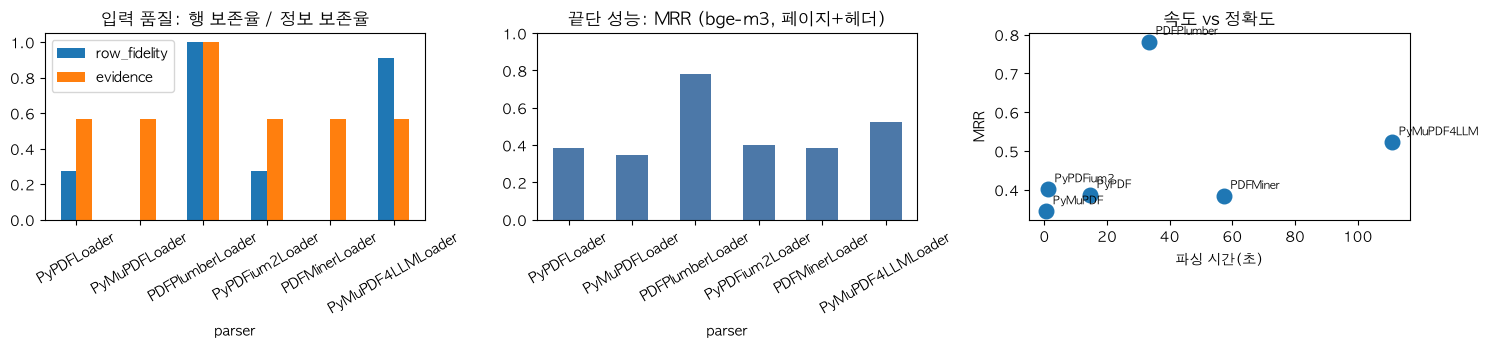

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
parser_df[["row_fidelity", "evidence"]].plot.bar(ax=axes[0], rot=30); axes[0].set_title("입력 품질: 행 보존율 / 정보 보존율"); axes[0].set_ylim(0, 1.05)
parser_df["MRR"].plot.bar(ax=axes[1], rot=30, color="#4c78a8"); axes[1].set_title("끝단 성능: MRR (bge-m3, 페이지+헤더)"); axes[1].set_ylim(0, 1)
axes[2].scatter(parser_df["parse_sec"], parser_df["MRR"], s=110)
for k, r in parser_df.iterrows(): axes[2].annotate(k.replace("Loader", ""), (r["parse_sec"], r["MRR"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
axes[2].set_xlabel("파싱 시간(초)"); axes[2].set_ylabel("MRR"); axes[2].set_title("속도 vs 정확도")
plt.tight_layout(); plt.show()

### 2.4 결론 — 로더 선택

- **입력 품질(`row_fidelity`)과 끝단 성능(`MRR`)을 같이 봅니다.** 글자가 다 있어도(`evidence`↑) 표 행이 깨져 있으면 과목명↔학수번호 대응을 임베딩이 복구하지 못합니다.
- `dept_pages` 가 낮은 로더는 페이지 제목(`OO학과 N학년`)이 쪼개져 읽혀서 **학과 메타데이터·헤더를 못 붙입니다.** 파서 선택이 메타데이터 품질까지 좌우하는 셈입니다.
- `PDFMinerLoader` 처럼 **쪽 정보가 사라진 채** 문서 1개로 나오는 로더는 후처리(쪽 분할)가 필요합니다. 로더마다 반환 형식이 다르다는 점은 LangChain 이 추상화해 주지 못하는 부분입니다.
- `PyMuPDF4LLMLoader` 는 표를 마크다운으로 만들어 구조를 보존하지만 가장 느리고 노이즈(`<br>`)가 섞입니다.
- 속도와 정확도는 trade-off 입니다. 문서가 수만 쪽이면 선택이 달라질 수 있습니다.

In [9]:
BEST_PARSER = parser_df.sort_values(["MRR", "row_fidelity"], ascending=False).index[0]
PAGE_TEXTS = PARSED[BEST_PARSER][0]
PAGE_DOCS = page_docs(PAGE_TEXTS)
DEPTS = sorted({d.metadata["dept"] for d in PAGE_DOCS if d.metadata["dept"]}, key=len, reverse=True)

def detect_dept(question):
    # 질문에 학과명이 정확히 하나만 등장하면 그 학과를 반환 (메타데이터 필터용)
    qn, found = norm(question), []
    for d in DEPTS:
        if d in qn: found.append(d); qn = qn.replace(d, "")
    return found[0] if len(found) == 1 else None

print(f"▶ 선정된 로더: {BEST_PARSER}  (MRR={parser_df.loc[BEST_PARSER, 'MRR']:.3f})")
print(f"  페이지 문서 {len(PAGE_DOCS)}개 · 학과 메타데이터가 붙은 페이지 {sum(1 for d in PAGE_DOCS if d.metadata['dept'])} · 학과 수 {len(DEPTS)}")
print("  detect_dept 예:", detect_dept("컴퓨터공학과 3학년 운영체제 학수번호는?"))
print("  Document 예:", {k: v for k, v in PAGE_DOCS[190].metadata.items()}, "|", repr(PAGE_DOCS[190].page_content[:40]))

▶ 선정된 로더: PDFPlumberLoader  (MRR=0.782)
  페이지 문서 229개 · 학과 메타데이터가 붙은 페이지 139 · 학과 수 81
  detect_dept 예: 컴퓨터공학과
  Document 예: {'page': 197, 'dept': '건축공학부[건축디자인전공]', 'source': 'curriculum_2026.pdf'} | '건축디자인전공\n건축공학부[건축디자인전공] 1학년\n1 학 기 2 학 기\n이'


## 3. 청킹 전략 비교 (`langchain_text_splitters`)

LangChain 의 `TextSplitter` 는 `split_documents(docs)` 로 **메타데이터(쪽·학과)를 유지한 채** 청크를 만들어 줍니다.

| 후보 | LangChain 구현 | 기대 장점 | 기대 단점 |
|---|---|---|---|
| `fixed` | `CharacterTextSplitter(separator="")` | 단순, 크기 균일 | 표의 행·문장 중간에서 끊김 |
| `recursive` | `RecursiveCharacterTextSplitter` | 범용 기본값, 문단→줄→공백 순 분할 + overlap | 표 구조는 모름 |
| `page` | 분할 없음 (페이지 = 청크) | 구조·맥락 최대 보존 | 청크가 큼 |
| `structure` | **직접 구현** (`OO학과 N학년` 블록) | 이 문서 구조에 최적 | 문서마다 규칙을 짜야 함 |
| `semantic` | `SemanticChunker` (`langchain_experimental`) | 의미 단위 분할 | 느리고 표처럼 짧은 줄엔 불안정 |

추가 옵션 `+hdr` : 청크 앞에 `[p.194 | 소프트웨어융합학과]` 헤더를 붙입니다. 청크가 "어느 학과의 것인지" 알려 주는 가장 값싼 방법입니다.

> 구조 기반 청킹처럼 **도메인 지식이 필요한 분할은 LangChain 이 대신해 주지 않습니다.** 직접 짠 함수도 `Document` 를 돌려주기만 하면 나머지 파이프라인에 그대로 연결됩니다.

In [10]:
from langchain_text_splitters import CharacterTextSplitter, RecursiveCharacterTextSplitter
from langchain_experimental.text_splitter import SemanticChunker

def split_fixed(docs, size=500, overlap=0):
    return CharacterTextSplitter(separator="", chunk_size=size, chunk_overlap=overlap).split_documents(docs)

def split_recursive(docs, size=500, overlap=75):
    return RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=overlap).split_documents(docs)

def split_structure(docs, max_chars=1200):
    # 학과 교과과정 페이지: 'OO학과 N학년' 줄마다 새 블록 + 헤더에 학년 표기. 그 외 페이지: 재귀 분할(800자)
    fallback = RecursiveCharacterTextSplitter(chunk_size=800, chunk_overlap=100)
    inner = RecursiveCharacterTextSplitter(chunk_size=max_chars, chunk_overlap=0)
    out = []
    for d in docs:
        if not d.metadata["dept"]:
            out += with_header(fallback.split_documents([d])); continue
        blocks, cur, grade = [], [], ""
        for line in d.page_content.split("\n"):
            m = GRADE_RE.match(clean_line(line))
            if m and cur and any(GRADE_RE.match(clean_line(x)) for x in cur):
                blocks.append((grade, "\n".join(cur))); cur = []
            if m: grade = (m.group(2) or m.group(3)) + "학년"
            cur.append(line)
        blocks.append((grade, "\n".join(cur)))
        for g, b in blocks:
            sub = inner.split_documents([Document(page_content=b, metadata=d.metadata)])
            out += with_header(sub, extra_fn=lambda _d, g=g: f" {g}" if g else "")
    return out

def split_semantic(docs, key=BASE_EMBED, percentile=90):
    # 줄 단위로 임베딩해서 인접 줄 사이 거리가 큰(상위 10%) 지점에서 분할
    chunker = SemanticChunker(PrefixCachedEmbeddings(key, batch=64), breakpoint_threshold_type="percentile",
                              breakpoint_threshold_amount=percentile, sentence_split_regex=r"\n+")
    return with_header(chunker.split_documents(docs))

def chunk_stats(chunks):
    n = np.array([len(raw_text(c)) for c in chunks])
    return dict(n_chunks=len(chunks), avg_len=n.mean(), p95_len=np.percentile(n, 95), max_len=n.max())

### 3.1 후보 구현과 통계

In [11]:
CANDIDATES = {
    "fixed_500":         lambda: split_fixed(PAGE_DOCS, 500, 0),
    "recursive_500":     lambda: split_recursive(PAGE_DOCS, 500, 75),
    "recursive_500+hdr": lambda: with_header(split_recursive(PAGE_DOCS, 500, 75)),
    "page":              lambda: list(PAGE_DOCS),
    "page+hdr":          lambda: with_header(PAGE_DOCS),
    "structure":         lambda: split_structure(PAGE_DOCS),
    "semantic":          lambda: split_semantic(PAGE_DOCS),
}
CHUNK_SETS = {}
for name, fn in CANDIDATES.items():
    t = time.perf_counter(); chunks = fn()
    for i, c in enumerate(chunks): c.metadata["chunk_id"] = i          # 검색 결과를 청크 번호로 되돌리기 위한 id
    CHUNK_SETS[name] = chunks
    print(f"{name:20s} {len(chunks):5d} 청크  ({time.perf_counter() - t:5.1f}s)")

for name in ["fixed_500", "structure"]:
    c = [c for c in CHUNK_SETS[name] if c.metadata["page"] == 194][1]
    print(f"\n━━━ {name} · 194쪽의 청크 예시 ({len(raw_text(c))}자) ━━━\n{c.page_content}")

fixed_500              682 청크  (  0.1s)
recursive_500          741 청크  (  0.0s)
recursive_500+hdr      741 청크  (  0.0s)
page                   229 청크  (  0.0s)
page+hdr               229 청크  (  0.0s)
structure              488 청크  (  0.0s)
semantic              1467 청크  (  1.3s)

━━━ fixed_500 · 194쪽의 청크 예시 (499자) ━━━
sw심화)통신프로그래밍 - - 704836 3 3
엔지니어앙트레프레너십 - - 190426 1 1
개 설 학 점 계 22 23 21 21
일 반 선 택 학 점 계
이 수 학 점 한 계 19 19
※ 기본소양 권장교과목: 제2외국어와한문(교양한문(1)), 의사소통(CTO특강)
※ (sw심화)표기 교과목은 SW/데이터활용역량인증의 ‘전문대체인정교과목’에 해당하며, 이는 인증트랙교과목의 심화모듈 교과목을 대체함.
소프트웨어융합학과 4학년
1 학 기 2 학 기
이수 학수 학수
교 과 목 비 고
구분 번호 번호
학점 시수 학점 시수
기본 핵심
법과생활(6영역) 산업·데이터공학의이해 004189 3 3 - -
소양 교양
전공
(sw심화)종합설계(2) 부학기 3 4 704814 3 4
필수
(sw심화)종합설계(1) 704711 3 3 부학기 3 3
(sw심화)가상현실프로그래밍 704713 3 3 - -
(sw심화)소프트웨어공학 704805 3 3 - -
(sw심화)컴퓨터보안 704811 3 3

━━━ structure · 194쪽의 청크 예시 (660자) ━━━
[p.194 | 소프트웨어융합학과 4학년]
소프트웨어융합학과 4학년
1 학 기 2 학 기
이수 학수 학수
교 과 목 비 고
구분 번호 번호
학점 시수 학점 시수
기본 핵심
법과생활(6영역) 산업·데이터공학의이해 004189 3 3 - -
소양 교양
전

### 3.2 청크 길이 분포

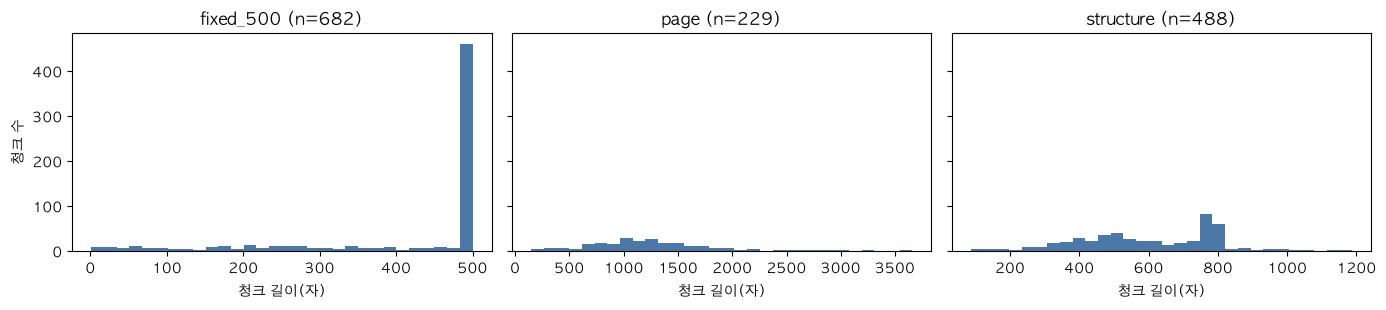

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, name in zip(axes, ["fixed_500", "page", "structure"]):
    ax.hist([len(raw_text(c)) for c in CHUNK_SETS[name]], bins=30, color="#4c78a8")
    ax.set_title(f"{name} (n={len(CHUNK_SETS[name])})"); ax.set_xlabel("청크 길이(자)")
axes[0].set_ylabel("청크 수"); plt.tight_layout(); plt.show()

### 3.3 청킹 전략 비교 결과 (임베딩 = bge-m3 고정)

,n_chunks,avg_len,p95_len,max_len,embed_sec,R@1,R@3,R@5,MRR
chunker,,,,,,,,,
fixed_500,682,415.402,500.000,500,35.112,0.455,0.636,0.727,0.567
recursive_500,741,420.119,498.000,500,38.278,0.409,0.682,0.727,0.539
recursive_500+hdr,741,420.119,498.000,500,39.456,0.455,0.682,0.727,0.589
page,229,1238.057,2348.400,3660,36.127,0.455,0.909,1.000,0.695
page+hdr,229,1238.057,2348.400,3660,37.042,0.591,0.932,1.000,0.782
structure,488,600.285,868.250,1188,35.661,0.568,0.864,0.864,0.719
semantic,1467,192.418,606.000,1710,47.092,0.136,0.273,0.409,0.282


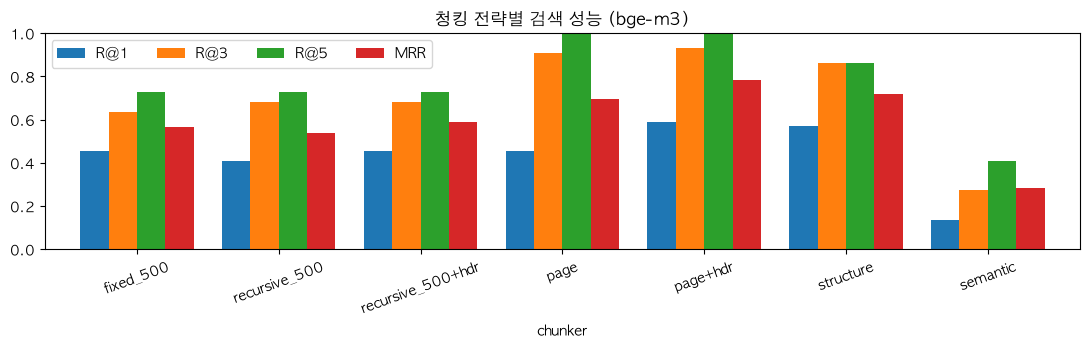

In [13]:
rows = []
for name, chunks in CHUNK_SETS.items():
    df, dvec, qvec, sec = eval_dense(chunks, emb_base)
    rows.append(dict(chunker=name, **chunk_stats(chunks), embed_sec=sec, **df[["R@1", "R@3", "R@5", "MRR"]].mean()))
chunk_df = pd.DataFrame(rows).set_index("chunker")
RESULTS["chunk"] = chunk_df
show_table(chunk_df, cols=["R@1", "R@3", "R@5", "MRR"])
ax = chunk_df[["R@1", "R@3", "R@5", "MRR"]].plot.bar(figsize=(11, 3.6), rot=20, width=0.8)
ax.set_title("청킹 전략별 검색 성능 (bge-m3)"); ax.set_ylim(0, 1); ax.legend(ncol=4); plt.tight_layout(); plt.show()

### 3.4 청크 크기 · overlap 변화 실험 (`RecursiveCharacterTextSplitter`)

> ⚠ 평가 문항이 22개(답이 있는 질문)뿐이라 **MRR 0.05 안팎의 차이는 우연일 수 있습니다.** 크기에 따라 단조롭게 오르내리지 않는 것도 그 때문입니다. 큰 차이(헤더 유무, page vs semantic 같은)만 의미 있게 읽으세요.

In [14]:
rows = []
for size in [300, 500, 800, 1200]:
    for ov_pct in [0, 15]:
        ch = split_recursive(PAGE_DOCS, size, int(size * ov_pct / 100))
        df, *_, sec = eval_dense(ch, emb_base)
        rows.append(dict(size=size, overlap_pct=ov_pct, n_chunks=len(ch), embed_sec=sec, **df[["R@1", "R@5", "MRR"]].mean()))
sweep_df = pd.DataFrame(rows); RESULTS["chunk_sweep"] = sweep_df
display(sweep_df.pivot(index="size", columns="overlap_pct", values="MRR").style.format(precision=3).set_caption("MRR (행: 청크 크기, 열: overlap %)"))

overlap_pct,0,15
size,,
300,0.419,0.499
500,0.506,0.539
800,0.431,0.654
1200,0.566,0.541


### 3.5 결론 — 청킹

- 위 표에서 **MRR 이 가장 높은 청킹**을 다음 장의 기본값으로 씁니다.
- 확인해 볼 것
  1. `recursive_500` 과 `recursive_500+hdr` 의 차이 → **헤더 한 줄**이 "어느 학과인지" 구분하는 데 얼마나 기여하는가
  2. `page` 는 R@5 는 높아도 R@1·MRR 은 어떤가 → 청크가 클수록 "찾기는 하지만 순위가 흐려지는" 경향
  3. `semantic` 은 시간 대비 이득이 있는가 → 표처럼 짧은 줄이 많은 문서에서는 이득이 작거나 불리
  4. 청크가 커지면 7장에서 LLM 프롬프트 토큰이 늘어난다

In [15]:
BEST_CHUNKER = chunk_df["MRR"].idxmax()
CHUNKS = CHUNK_SETS[BEST_CHUNKER]
CHUNK_TEXTS = [c.page_content for c in CHUNKS]
print(f"▶ 선정된 청킹: {BEST_CHUNKER}  (청크 {len(CHUNKS)}개, MRR={chunk_df.loc[BEST_CHUNKER, 'MRR']:.3f})")

▶ 선정된 청킹: page+hdr  (청크 229개, MRR=0.782)


## 4. 임베딩 모델 비교 (`OllamaEmbeddings`)

같은 청크(3장 우승), 같은 검색(코사인 유사도)에서 **임베딩 모델만** 바꿉니다. LangChain 에서는 `OllamaEmbeddings(model=...)` 의 `model` 만 바꾸면 됩니다.

| 후보 | 특징 (기대) |
|---|---|
| `bge-m3` | 다국어, 한국어 강점. 1024차원, 컨텍스트 8K |
| `nomic-embed-text` | 경량(274MB). 영어 중심 |
| `mxbai-embed-large` | 영어 벤치마크 우수. 한국어는? |
| `arctic-embed2` | 다국어 지원 (Snowflake) |
| `qwen3-embedding:0.6b` | 최신, 다국어. query 에 **instruction** 을 붙여 사용 |

> 모델마다 **query/document 접두어 규칙**이 다릅니다 (`EMBED_MODELS`). `OllamaEmbeddings` 는 접두어를 모르므로 `PrefixCachedEmbeddings` 가 대신 붙여 줍니다.

In [16]:
rows, EMBED_EVAL, EMBED_VECS, EMBEDDERS = [], {}, {}, {}
for key in EMBED_MODELS:
    emb = PrefixCachedEmbeddings(key); EMBEDDERS[key] = emb
    df, dvec, qvec, sec = eval_dense(CHUNKS, emb)
    EMBED_EVAL[key] = df; EMBED_VECS[key] = (dvec, qvec)
    rows.append(dict(model=key, dim=dvec.shape[1], index_sec=sec, vec_MB=dvec.nbytes / 1e6, **df[["R@1", "R@3", "R@5", "MRR"]].mean()))
embed_df = pd.DataFrame(rows).set_index("model")
RESULTS["embed"] = embed_df
show_table(embed_df, cols=["R@1", "R@3", "R@5", "MRR"])

,dim,index_sec,vec_MB,R@1,R@3,R@5,MRR
model,,,,,,,
bge-m3,1024,37.042,0.938,0.591,0.932,1.000,0.782
nomic-embed-text,768,18.695,0.703,0.341,0.523,0.636,0.486
mxbai-embed-large,1024,31.353,0.938,0.227,0.432,0.477,0.357
arctic-embed2,1024,39.683,0.938,0.341,0.682,0.818,0.572
qwen3-embedding,1024,98.911,0.938,0.614,0.795,0.909,0.758


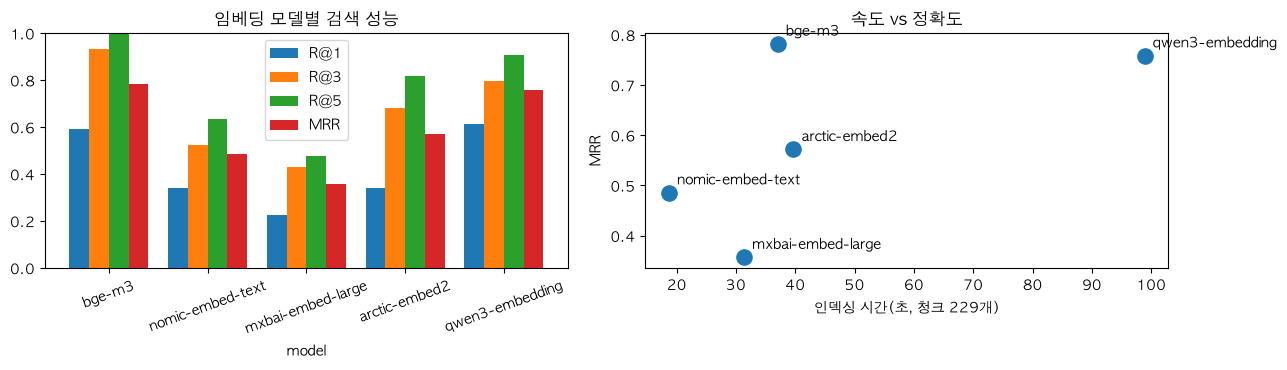

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
embed_df[["R@1", "R@3", "R@5", "MRR"]].plot.bar(ax=axes[0], rot=20, width=0.8); axes[0].set_title("임베딩 모델별 검색 성능"); axes[0].set_ylim(0, 1)
axes[1].scatter(embed_df["index_sec"], embed_df["MRR"], s=120)
for k, r in embed_df.iterrows(): axes[1].annotate(k, (r["index_sec"], r["MRR"]), textcoords="offset points", xytext=(6, 6))
axes[1].set_xlabel(f"인덱싱 시간(초, 청크 {len(CHUNKS)}개)"); axes[1].set_ylabel("MRR"); axes[1].set_title("속도 vs 정확도")
plt.tight_layout(); plt.show()

### 4.1 질문 유형별 · 질문별 분석

In [18]:
by_type = pd.DataFrame({k: df.groupby(df.index.map(QTYPE))["MRR"].mean() for k, df in EMBED_EVAL.items()}).T
display(by_type.style.format(precision=3).highlight_max(color="#cfe8cf").set_caption("유형별 MRR"))
per_q = pd.DataFrame({k: df["R@5"] for k, df in EMBED_EVAL.items()})
per_q.insert(0, "question", [QA_BY_ID[i]["question"][:34] + "…" for i in per_q.index])
display(per_q.style.format(precision=2).background_gradient(cmap="RdYlGn", subset=list(EMBED_MODELS), vmin=0, vmax=1).set_caption("질문별 R@5 (초록=찾음, 빨강=못 찾음)"))

id,multi,rule,table
bge-m3,0.500,0.800,0.792
nomic-embed-text,1.000,0.211,0.649
mxbai-embed-large,0.500,0.386,0.324
arctic-embed2,1.000,0.465,0.616
qwen3-embedding,1.000,0.622,0.840


,question,bge-m3,nomic-embed-text,mxbai-embed-large,arctic-embed2,qwen3-embedding
id,,,,,,
q01,소프트웨어융합학과 3학년 1학기에 개설되는 운영체제의 학수번호…,1.00,1.00,0.00,1.00,1.00
q02,컴퓨터공학과 3학년 2학기 운영체제의 학수번호는?…,1.00,1.00,1.00,1.00,1.00
q03,소프트웨어융합학과 4학년 졸업논문은 몇 학점인가?…,1.00,1.00,0.00,1.00,1.00
q04,소프트웨어융합학과 2학년 1학기 선형대수학의 학수번호는?…,1.00,1.00,0.00,1.00,1.00
q05,소프트웨어융합학과 4학년에서 인공지능은 몇 학기에 개설되고 학…,1.00,1.00,0.00,1.00,1.00
q06,컴퓨터공학과 4학년 졸업논문의 학수번호는?…,1.00,1.00,1.00,1.00,1.00
q07,컴퓨터공학과 3학년 1학기에 개설된 컴퓨터구조의 학수번호는?…,1.00,1.00,1.00,1.00,1.00
q08,의료헬스케어AI전공 3학년 2학기 기계학습기초의 학수번호는?…,1.00,1.00,1.00,1.00,1.00
q09,의료헬스케어AI전공 4학년 시스템설계(캡스톤디자인)의 학수번호…,1.00,1.00,0.00,1.00,1.00


### 4.2 결론 — 임베딩

- 한국어 문서에서 **다국어 모델과 영어 중심 모델의 격차**를 숫자로 확인합니다.
- 정확도가 비슷하면 **차원·속도·모델 크기**가 선택 기준입니다.
- 모든 모델이 공통으로 틀리는 질문이 있다면 임베딩이 아니라 **청킹/검색 방식/데이터** 문제일 가능성이 큽니다. (6장에서 BM25 와 필터로 보완)

In [19]:
BEST_EMBED = embed_df["MRR"].idxmax()
EMB = EMBEDDERS[BEST_EMBED]
DVEC, QVEC_ANS = EMBED_VECS[BEST_EMBED]
print(f"▶ 선정된 임베딩: {BEST_EMBED}  (MRR={embed_df.loc[BEST_EMBED, 'MRR']:.3f}, 차원={DVEC.shape[1]})")

▶ 선정된 임베딩: bge-m3  (MRR=0.782, 차원=1024)


## 5. 벡터스토어 비교 (LangChain integrations)

같은 청크, 같은 임베딩 벡터를 **모든 벡터스토어에 똑같이 적재**합니다. LangChain 덕분에 생성·검색 코드는 거의 같지만, **메타데이터 필터 문법은 스토어마다 다릅니다.**

| 후보 | LangChain 클래스 | 필터 문법 | 기대 |
|---|---|---|---|
| In-memory (기준선) | `InMemoryVectorStore` | `lambda doc: bool` | 정확 검색 기준, 영속화 없음 |
| ChromaDB | `langchain_chroma.Chroma` | `{"dept": "컴퓨터공학과"}` | 쉬움, 사전 필터 |
| FAISS | `FAISS` | `{"dept": ...}` + `fetch_k` | 빠름, **사후 필터**(`fetch_k` 가 작으면 정답 누락) |
| Qdrant (로컬) | `QdrantVectorStore` | `qdrant_client.models.Filter(...)` | 필터 강력, 문법 장황 |
| LanceDB | `LanceDB` (community) | SQL 문자열 `"metadata.dept = '...'"` | 가벼운 파일 기반 |

### 5.1 같은 벡터를 모든 스토어에 넣기

`LookupEmbeddings` 로 "텍스트 → 이미 계산한 벡터" 표를 만들어 넘기면, 각 스토어가 `embed_documents` 를 호출해도 **재계산 없이 동일한 벡터**를 받습니다.

In [20]:
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_chroma import Chroma
from langchain_community.vectorstores import FAISS, LanceDB
from langchain_qdrant import QdrantVectorStore
from qdrant_client import models as qm
import lancedb

DIM = DVEC.shape[1]
TABLE = dict(zip(CHUNK_TEXTS, DVEC.tolist()))
TABLE.update({q["question"]: v.tolist() for q, v in zip(QA_ANS, QVEC_ANS)})   # 질문 → 질의 벡터 (검색기가 embed_query 를 불러도 재계산 안 함)
LOOKUP = LookupEmbeddings(TABLE, DIM, fallback=EMB)                            # 표에 없는 새 질문은 진짜 Ollama 로 임베딩

BUILDERS = {
    "InMemory": lambda docs, emb, path: InMemoryVectorStore.from_documents(docs, emb),
    "Chroma":   lambda docs, emb, path: Chroma.from_documents(docs, emb, collection_name="chunks", persist_directory=str(path),
                                                              collection_metadata={"hnsw:space": "cosine"}),
    "FAISS":    lambda docs, emb, path: FAISS.from_documents(docs, emb),
    "Qdrant":   lambda docs, emb, path: QdrantVectorStore.from_documents(docs, emb, path=str(path), collection_name="chunks"),
    "LanceDB":  lambda docs, emb, path: LanceDB.from_documents(docs, emb, connection=lancedb.connect(str(path)), table_name="chunks"),
}
FILTERS = {   # 같은 조건("dept == X")인데 스토어마다 표현이 다르다
    "InMemory": lambda d: (lambda doc: doc.metadata["dept"] == d),
    "Chroma":   lambda d: {"dept": d},
    "FAISS":    lambda d: {"dept": d},
    "Qdrant":   lambda d: qm.Filter(must=[qm.FieldCondition(key="metadata.dept", match=qm.MatchValue(value=d))]),
    "LanceDB":  lambda d: f"metadata.dept = '{d}'",
}

def vs_search(name, store, vec, k, dept=None):
    vec = [float(x) for x in vec]            # Qdrant 는 numpy 배열을 거부하고 list 만 받는다
    kw = {}
    if dept: kw["filter"] = FILTERS[name](dept)
    if dept and name == "FAISS": kw["fetch_k"] = len(store.docstore._dict)   # FAISS 는 사후 필터: 후보를 넉넉히 가져와야 한다
    return [d.metadata["chunk_id"] for d in store.similarity_search_by_vector(vec, k=k, **kw)]

def bench_store(name, docs, emb, qvecs, k=5, reps=3):
    path = Path(tempfile.mkdtemp(dir=WORK))
    t0 = time.perf_counter(); store = BUILDERS[name](docs, emb, path); build_s = time.perf_counter() - t0
    if hasattr(store, "save_local"): store.save_local(str(path))      # FAISS 는 명시적으로 저장해야 디스크에 남는다
    lat = []
    for _ in range(reps):
        for q in qvecs:
            t = time.perf_counter(); vs_search(name, store, q, k); lat.append((time.perf_counter() - t) * 1000)
    return store, dict(store=name, build_s=build_s, p50_ms=np.percentile(lat, 50), p95_ms=np.percentile(lat, 95), disk_MB=dir_size_mb(path))

### 5.2 적재 · 검색 속도 · 정확도 (책자 규모)

- `top5 일치율` : `InMemoryVectorStore`(정확 검색)와 상위 5개가 얼마나 겹치는가
- `MRR` : 같은 평가셋으로 검색 정확도를 다시 측정 → **스토어를 바꿔도 정확도는 거의 같아야 정상**

In [21]:
rel_best = build_relevance(CHUNKS, QA_ANS)
STORES, rows = {}, []
for name in BUILDERS:
    try:
        store, r = bench_store(name, CHUNKS, LOOKUP, [v for v in QVEC_ANS]); STORES[name] = store
        rows.append(r)
    except Exception as e:
        print(f"⚠ {name} 실패: {type(e).__name__}: {str(e)[:120]}")
exact = {q["id"]: vs_search("InMemory", STORES["InMemory"], qv, 5) for q, qv in zip(QA_ANS, QVEC_ANS)}
for r in rows:
    n = r["store"]
    rank = {q["id"]: vs_search(n, STORES[n], qv, 20) for q, qv in zip(QA_ANS, QVEC_ANS)}
    r["top5_agree"] = np.mean([len(set(rank[i][:5]) & set(exact[i])) / 5 for i in exact])
    r["MRR"] = score_rankings(rank, rel_best)["MRR"].mean()
vdb_df = pd.DataFrame(rows).set_index("store"); RESULTS["vdb"] = vdb_df
display(vdb_df.style.format(precision=3).highlight_min(subset=["build_s", "p50_ms", "p95_ms", "disk_MB"], color="#cfe8cf")
        .highlight_max(subset=["top5_agree", "MRR"], color="#cfe8cf"))

,build_s,p50_ms,p95_ms,disk_MB,top5_agree,MRR
store,,,,,,
InMemory,0.001,4.123,4.237,0.000,1.000,0.782
Chroma,0.312,0.667,0.727,6.535,1.000,0.782
FAISS,0.060,0.067,0.073,1.525,1.000,0.782
Qdrant,0.112,0.396,0.436,2.987,1.000,0.782
LanceDB,0.073,1.889,2.532,1.307,1.000,0.782


### 5.3 메타데이터 필터 검색

질문에 학과명이 하나만 있으면(`detect_dept`) 그 학과 청크 안에서만 검색해 봅니다. 확인할 것은 세 가지입니다.

1. 필터가 정확도를 올리는가
2. 스토어가 필터를 **제대로 지켰는가** (`filter_respected`)
3. 돌려줘야 할 개수(`avg_expected` = min(20, 그 학과의 청크 수))를 **다 돌려줬는가** (`avg_returned`) — 사후 필터 방식은 후보를 먼저 자르고 거르기 때문에 적게 돌려줄 수 있다

In [22]:
dept_of = {q["id"]: detect_dept(q["question"]) for q in QA_ANS}
filt_q = [(q, qv) for q, qv in zip(QA_ANS, QVEC_ANS) if dept_of[q["id"]]]
print(f"학과가 감지된 질문: {len(filt_q)} / {len(QA_ANS)}")
rel_f = {q["id"]: rel_best[q["id"]] for q, _ in filt_q}
# 필터를 정확히 지키면 돌려줘야 하는 개수 = min(20, 그 학과의 청크 수)
dept_count = pd.Series([c.metadata["dept"] for c in CHUNKS]).value_counts()
avg_expected = np.mean([min(20, dept_count.get(dept_of[q["id"]], 0)) for q, _ in filt_q])

rows = []
for name, store in STORES.items():
    try:
        base = {q["id"]: vs_search(name, store, qv, 20) for q, qv in filt_q}
        flt = {q["id"]: vs_search(name, store, qv, 20, dept=dept_of[q["id"]]) for q, qv in filt_q}
        respected = all(CHUNKS[i].metadata["dept"] == dept_of[q["id"]] for q, _ in filt_q for i in flt[q["id"]])
        rows.append(dict(store=name, MRR_no_filter=score_rankings(base, rel_f)["MRR"].mean(), MRR_dept_filter=score_rankings(flt, rel_f)["MRR"].mean(),
                         filter_respected=respected, avg_returned=np.mean([len(v) for v in flt.values()]), avg_expected=avg_expected))
    except Exception as e:
        rows.append(dict(store=name, MRR_no_filter=np.nan, MRR_dept_filter=np.nan, filter_respected=f"오류: {type(e).__name__}", avg_returned=np.nan, avg_expected=avg_expected))
filter_df = pd.DataFrame(rows).set_index("store"); RESULTS["vdb_filter"] = filter_df
display(filter_df.style.format(precision=3))

학과가 감지된 질문: 13 / 22


,MRR_no_filter,MRR_dept_filter,filter_respected,avg_returned,avg_expected
store,,,,,
InMemory,0.785,0.615,True,2.000,2.000
Chroma,0.785,0.615,True,2.000,2.000
FAISS,0.785,0.615,True,2.000,2.000
Qdrant,0.785,0.615,True,2.000,2.000
LanceDB,0.785,0.615,True,1.923,2.000


> 💡 **필터가 항상 이득은 아닙니다 — 이 실험에서는 오히려 MRR 이 떨어집니다.**
> 1. **질문 속 학과명 ≠ 찾는 페이지의 학과.** "산업·데이터공학과의 MSC 학점은?", "게임소프트웨어전공의 MSC 학점은?" 은 학과명이 나오지만 정답은 **졸업요건(일반 규정) 페이지**에 있고, 그 페이지에는 `dept` 메타데이터가 없어서 필터가 정답을 통째로 걸러냅니다.
> 2. **메타데이터가 비어 있는 페이지**(예: 홍익챌린지 학수번호 목록)도 마찬가지입니다.
>
> 필터는 "메타데이터 품질" + "질문 의도 파악(이 질문이 학과 교과과정 표를 묻는가?)" 이 함께 갖춰져야 이득입니다.
>
> 또한 `avg_returned` 가 `avg_expected` 보다 작다면 해당 스토어가 **사후 필터**(top-k 를 먼저 자르고 거름)로 동작해서 정답 후보를 놓친 것입니다. 같은 `filter=` 인자여도 의미가 다릅니다. **LangChain 이 인터페이스는 통일해도 동작까지 통일해 주지는 않습니다.**
>
> (참고: 페이지 단위 청크에서는 한 학과가 청크 2개뿐이라 `avg_expected` 자체가 작습니다. 청크를 잘게 쪼갠 설정으로 바꾸면 차이가 더 크게 드러납니다.)

### 5.4 규모가 커지면? (합성 벡터 스케일 테스트)

책자는 청크가 수백 개라 어떤 스토어를 써도 차이가 거의 없습니다. 합성 랜덤 벡터로 규모를 키워 봅니다. (`SCALE_N` 을 올리면 차이가 더 커지지만 오래 걸립니다.)

In [23]:
SCALE_N = 20_000
rng = np.random.default_rng(0)
big = l2norm(rng.standard_normal((SCALE_N, DIM)).astype(np.float32))
big_docs = [Document(page_content=f"doc{i}", metadata=dict(chunk_id=i, page=i % 237, dept=f"dept{i % 20}")) for i in range(SCALE_N)]
big_emb = LookupEmbeddings({d.page_content: v.tolist() for d, v in zip(big_docs, big)}, DIM)
big_q = l2norm(rng.standard_normal((50, DIM)).astype(np.float32))

rows, big_stores = [], {}
for name in BUILDERS:
    try:
        store, r = bench_store(name, big_docs, big_emb, [q.tolist() for q in big_q], reps=2); big_stores[name] = store; rows.append(r)
    except Exception as e:
        print(f"⚠ {name} 실패: {type(e).__name__}: {str(e)[:120]}")
exact_big = [vs_search("InMemory", big_stores["InMemory"], q.tolist(), 5) for q in big_q[:20]]
for r in rows:
    r["top5_agree"] = np.mean([len(set(vs_search(r["store"], big_stores[r["store"]], q.tolist(), 5)) & set(e)) / 5 for q, e in zip(big_q[:20], exact_big)])
scale_df = pd.DataFrame(rows).set_index("store"); RESULTS["vdb_scale"] = scale_df
print(f"벡터 {SCALE_N:,}개 × {DIM}차원 (랜덤 벡터라 ANN 의 top5 일치율은 '최악 사례')")
display(scale_df.style.format(precision=3).highlight_min(subset=["build_s", "p50_ms", "p95_ms"], color="#cfe8cf").highlight_max(subset=["top5_agree"], color="#cfe8cf"))
del big_stores

벡터 20,000개 × 1024차원 (랜덤 벡터라 ANN 의 top5 일치율은 '최악 사례')


,build_s,p50_ms,p95_ms,disk_MB,top5_agree
store,,,,,
InMemory,0.124,350.871,384.395,0.000,1.000
Chroma,19.515,3.258,3.808,120.878,0.270
FAISS,0.358,1.645,1.724,84.519,1.000
Qdrant,12.246,12.779,15.939,206.640,1.000
LanceDB,0.527,10.227,11.838,82.634,1.000


### 5.5 결론 — 벡터스토어

| 상황 | 추천 |
|---|---|
| 수천 개 이하 프로토타입 | `InMemoryVectorStore` / `Chroma` — 충분히 빠르고 코드가 짧다 |
| 필터 + 영속화 | `Chroma` / `QdrantVectorStore` / `LanceDB` |
| 순수 속도, 직접 제어 | `FAISS` (필터는 사후 필터, 저장은 `save_local`) |
| 운영·확장 | Qdrant 서버, pgvector 등 |

- 책자 규모에서는 **정확도 차이가 없습니다** → 선택 기준은 정확도가 아니라 **기능·운영·필터 동작 방식**입니다.
- LangChain 의 `VectorStore` 인터페이스(`from_documents`, `similarity_search_by_vector`)는 통일되어 있어 **교체 비용이 낮습니다.** 단 필터 문법·동작은 스토어마다 달라서 교체 시 다시 검증해야 합니다.

이후 6장은 `Chroma` 를 사용합니다.

## 6. 리트리버 비교

LangChain 에서 검색 로직은 모두 **`Retriever`** (`invoke(query) -> list[Document]`) 로 통일됩니다. 그래서 서로 조합하거나(`EnsembleRetriever`) 감쌀 수 있습니다.

| 후보 | LangChain 클래스 | 기대 장점 | 기대 단점 |
|---|---|---|---|
| Dense | `Chroma.as_retriever()` | 표현이 달라도 의미로 찾음 | 코드·숫자에 약함 |
| BM25 (공백 토큰) | `BM25Retriever` | 정확한 키워드에 강함 | 조사 때문에 매칭 실패 |
| BM25 (Kiwi 형태소) | `BM25Retriever(preprocess_func=kiwi)` | 조사 분리로 한국어 개선 | 형태소 분석 비용 |
| Hybrid | `EnsembleRetriever` (RRF) | 서로의 약점 보완 | 구성 요소 증가 |
| + 학과 필터 | 직접 만든 `DeptFilterRetriever` | 동명 과목 혼동 제거 | 메타데이터·질문 의도가 틀리면 정답 소실 |

> `EnsembleRetriever` 는 LangChain 1.x 에서 `langchain_classic` 패키지로 옮겨졌습니다. 버전이 바뀌면 import 경로가 바뀔 수 있다는 점도 LangChain 사용 시의 현실적인 부담입니다.

In [24]:
from langchain_community.retrievers import BM25Retriever
from langchain_classic.retrievers import EnsembleRetriever
from langchain_core.retrievers import BaseRetriever
from kiwipiepy import Kiwi

kiwi = Kiwi()
KEEP_TAGS = {"NNG", "NNP", "NNB", "SL", "SN", "XR", "VV", "VA"}
def tok_ws(t): return t.lower().split()
def tok_kiwi(t): return [x.form.lower() for x in kiwi.tokenize(t) if x.tag in KEEP_TAGS]
print("공백 토큰 :", tok_ws("소프트웨어융합학과 3학년 운영체제의 학수번호는?"))
print("Kiwi 토큰 :", tok_kiwi("소프트웨어융합학과 3학년 운영체제의 학수번호는?"))

VS = STORES["Chroma"]
K_ALL, K = len(CHUNKS), 20

def dense_r(k): return VS.as_retriever(search_kwargs={"k": k})
def bm25_r(tok, k): return BM25Retriever.from_documents(CHUNKS, preprocess_func=tok, k=k)

class DeptFilterRetriever(BaseRetriever):
    # 질문에서 학과를 감지하면 그 학과 청크만 남긴다. base 는 전체 순위를 돌려줘야(k=전체) 필터 후에도 상위 K개가 남는다.
    base: BaseRetriever
    k: int = 20
    def _get_relevant_documents(self, query, *, run_manager=None):
        dept = detect_dept(query)
        docs = self.base.invoke(query)
        if dept: docs = [d for d in docs if d.metadata["dept"] == dept]
        return docs[:self.k]

def ensemble(rs): return EnsembleRetriever(retrievers=rs, weights=[0.5] * len(rs), id_key="chunk_id")   # 가중 RRF

RETRIEVERS = {
    "dense":              dense_r(K),
    "bm25 (공백)":         bm25_r(tok_ws, K),
    "bm25 (kiwi)":        bm25_r(tok_kiwi, K),
    "hybrid":             ensemble([dense_r(K), bm25_r(tok_kiwi, K)]),
    "dense + 학과필터":     DeptFilterRetriever(base=dense_r(K_ALL)),
    "hybrid + 학과필터":    ensemble([DeptFilterRetriever(base=dense_r(K_ALL)), DeptFilterRetriever(base=bm25_r(tok_kiwi, K_ALL))]),
}
print("리트리버:", list(RETRIEVERS))
print("예:", [(d.metadata["page"], d.metadata["dept"]) for d in RETRIEVERS["hybrid"].invoke(QA_ANS[0]["question"])[:3]])

공백 토큰 : ['소프트웨어융합학과', '3학년', '운영체제의', '학수번호는?']
Kiwi 토큰 : ['소프트웨어', '융합', '학과', '3', '학년', '운영', '체제', '학', '수', '번호']
리트리버: ['dense', 'bm25 (공백)', 'bm25 (kiwi)', 'hybrid', 'dense + 학과필터', 'hybrid + 학과필터']
예: [(194, '소프트웨어융합학과'), (193, '소프트웨어융합학과'), (31, '')]


### 6.1 리트리버별 성능

In [25]:
rows, RETR_EVAL = [], {}
for name, r in RETRIEVERS.items():
    t0 = time.perf_counter()
    rank = {q["id"]: [d.metadata["chunk_id"] for d in r.invoke(q["question"])] for q in QA_ANS}
    ms = (time.perf_counter() - t0) / len(QA_ANS) * 1000
    df = score_rankings(rank, rel_best); RETR_EVAL[name] = df
    rows.append(dict(retriever=name, ms_per_query=ms, **df[["R@1", "R@3", "R@5", "MRR"]].mean()))
retr_df = pd.DataFrame(rows).set_index("retriever"); RESULTS["retrieval"] = retr_df
show_table(retr_df, cols=["R@1", "R@3", "R@5", "MRR"])
by_type = pd.DataFrame({k: df.groupby(df.index.map(QTYPE))["MRR"].mean() for k, df in RETR_EVAL.items()}).T
display(by_type.style.format(precision=3).highlight_max(color="#cfe8cf").set_caption("유형별 MRR"))

,ms_per_query,R@1,R@3,R@5,MRR
retriever,,,,,
dense,1.742,0.591,0.932,1.000,0.782
bm25 (공백),0.167,0.341,0.523,0.614,0.504
bm25 (kiwi),0.442,0.432,0.614,0.750,0.606
hybrid,1.591,0.682,0.955,1.000,0.812
dense + 학과필터,5.081,0.545,0.795,0.818,0.682
hybrid + 학과필터,5.856,0.545,0.818,0.818,0.674


id,multi,rule,table
dense,0.500,0.800,0.792
bm25 (공백),1.000,0.351,0.576
bm25 (kiwi),1.000,0.485,0.664
hybrid,0.500,0.781,0.861
dense + 학과필터,0.500,0.556,0.792
hybrid + 학과필터,0.500,0.537,0.792


### 6.2 결론 — 리트리버

- 학수번호·코드 질문(`table`)에서 **Dense 와 BM25 중 누가 강한지**, 규정 문장(`rule`)에서는 어떤지 유형별 표로 확인합니다.
- BM25 는 **토크나이저에 따라 성능이 크게 달라집니다.** 한국어는 형태소 분석이 사실상 필수입니다.
- Hybrid 는 한쪽이 틀릴 때 다른 쪽이 보완하므로 실패 케이스를 줄입니다.
- 학과 필터는 동명 과목 혼동은 줄여도 **질문에 학과명이 나온다고 그 학과 페이지를 찾는 건 아닙니다.** 졸업요건 같은 일반 규정 질문에서는 정답 페이지를 걸러내 `rule` 유형 점수가 떨어집니다. 필터를 쓰려면 질문 의도 분류가 먼저 필요합니다. (과제 3 참고)

In [26]:
BEST_RETRIEVER_NAME = retr_df["MRR"].idxmax()
BEST_RETRIEVER = RETRIEVERS[BEST_RETRIEVER_NAME]
print(f"▶ 선정된 리트리버: {BEST_RETRIEVER_NAME}  (MRR={retr_df.loc[BEST_RETRIEVER_NAME, 'MRR']:.3f})")

▶ 선정된 리트리버: hybrid  (MRR=0.812)


## 7. 생성 단계 (LCEL)

검색된 `Document` 를 프롬프트에 넣어 답을 만듭니다. LangChain 의 **LCEL(LangChain Expression Language)** 은 `|` 로 컴포넌트를 이어 붙입니다.

```python
chain = RAG_PROMPT | llm            # 프롬프트 → 모델
chain.batch(inputs, config={"max_concurrency": 8})   # 입력 여러 개를 병렬로
```

### 7.1 프롬프트와 모델 준비

핵심 규칙 3가지
1. **참고자료에 있는 내용만** 근거로 답한다 (환각 억제)
2. **학과·학년·학기가 일치하는 자료만** 쓴다 (이 문서의 대표 함정)
3. 근거가 없으면 정해진 문장으로 **거절**한다 → 문장이 고정되어야 자동 채점 가능

채점 기준: 답이 있는 질문은 정답 키워드가 **모두** 포함되면 정답 (`A|B` 로 쓰면 표기 차이 허용), `unanswerable` 은 "책자에서 확인할 수 없습니다" 로 거절하면 정답.

> 지연시간·토큰 수는 LangChain **콜백**(`BaseCallbackHandler`)으로 수집합니다. `batch` 는 결과만 돌려주기 때문에 호출별 시간은 콜백으로만 알 수 있습니다.

In [27]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_core.callbacks import BaseCallbackHandler
from langchain_openai import ChatOpenAI
from langchain_ollama import ChatOllama

SYS_RAG = ("당신은 대학 교과과정 책자를 안내하는 도우미입니다. 반드시 [참고자료]에 있는 내용만 근거로 한국어로 간결하게 답하세요. "
           "질문의 학과·학년·학기와 정확히 일치하는 자료만 사용하세요. "
           "참고자료에서 답을 찾을 수 없으면 다른 말 없이 정확히 '책자에서 확인할 수 없습니다.' 라고만 답하세요.")
SYS_NO_RAG = "당신은 대학 교과과정 안내 도우미입니다. 한국어로 한두 문장으로 간결히 답하세요. 모르면 '책자에서 확인할 수 없습니다.'라고만 답하세요."
RAG_PROMPT = ChatPromptTemplate.from_messages([("system", SYS_RAG), ("human", "[참고자료]\n{context}\n\n[질문]\n{question}")])
NORAG_PROMPT = ChatPromptTemplate.from_messages([("system", SYS_NO_RAG), ("human", "{question}")])

def make_llm(spec):
    prov, name = spec.split(":", 1)
    if prov == "openai":
        return ChatOpenAI(model=name, temperature=0, max_completion_tokens=400, timeout=60, max_retries=3)
    return ChatOllama(model=name, temperature=0, num_ctx=8192)       # 로컬 모델 (느림)

class CallTracker(BaseCallbackHandler):
    def __init__(self): self._t0, self.calls = {}, []      # calls: (초, 입력 토큰, 출력 토큰)
    def on_chat_model_start(self, serialized, messages, *, run_id, **kwargs): self._t0[run_id] = time.perf_counter()
    def on_llm_end(self, response, *, run_id, **kwargs):
        sec = time.perf_counter() - self._t0.pop(run_id, time.perf_counter())
        um = getattr(response.generations[0][0].message, "usage_metadata", None) or {}
        self.calls.append((sec, um.get("input_tokens", 0), um.get("output_tokens", 0)))
    @property
    def avg_sec(self): return float(np.mean([c[0] for c in self.calls])) if self.calls else np.nan
    @property
    def tps(self): return float(np.mean([c[2] / c[0] for c in self.calls if c[0] > 0])) if self.calls else np.nan

USAGE = {}   # 모델별 누적 토큰 사용량 (비용 확인용)
def msg_text(m): return m.content.strip() if isinstance(m.content, str) else "".join(p.get("text", "") for p in m.content if isinstance(p, dict)).strip()

def run_chain(model, inputs, prompt):
    tracker = CallTracker()
    msgs = (prompt | make_llm(model)).batch(inputs, config={"max_concurrency": MAX_WORKERS, "callbacks": [tracker]})
    u = USAGE.setdefault(model, dict(prompt=0, completion=0, calls=0))
    u["prompt"] += sum(c[1] for c in tracker.calls); u["completion"] += sum(c[2] for c in tracker.calls); u["calls"] += len(tracker.calls)
    return [msg_text(m) for m in msgs], tracker

def format_docs(docs):
    return "\n\n".join(f"[자료 {n} | p.{d.metadata['page']}" + (f" | {d.metadata['dept']}" if d.metadata["dept"] else "") + f"]\n{raw_text(d)}"
                       for n, d in enumerate(docs, 1))

def judge(q, answer):
    a = norm(answer)
    if q["type"] == "unanswerable": return "확인할수없" in a
    return "확인할수없" not in a and all(any(norm(alt) in a for alt in k.split("|")) for k in q["answer_keywords"])

GEN_K = 5
RANKED = {q["id"]: BEST_RETRIEVER.invoke(q["question"]) for q in QA}          # 질문별 검색 결과 (모델과 무관하므로 한 번만)
demo, tr = run_chain(FAST_MODEL, [dict(question=QA_BY_ID["q01"]["question"], context=format_docs(RANKED["q01"][:GEN_K]))], RAG_PROMPT)
print("Q.", QA_BY_ID["q01"]["question"]); print("A.", demo[0]); print("근거 페이지:", [d.metadata["page"] for d in RANKED["q01"][:GEN_K]])

Q. 소프트웨어융합학과 3학년 1학기에 개설되는 운영체제의 학수번호는?
A. 운영체제의 학수번호는 704512입니다.
근거 페이지: [194, 193, 31, 99, 56]


### 7.2 RAG 없이 질문하기 (기준선)

책자를 보여주지 않고 물어봅니다. 8장에서 RAG 적용 후와 비교합니다.

In [28]:
for qid in ["q01", "q10", "q16"]:
    q = QA_BY_ID[qid]
    ans, _ = run_chain(FAST_MODEL, [dict(question=q["question"])], NORAG_PROMPT)
    print(f"Q. {q['question']}\nA(RAG 없음). {ans[0]}\n정답 키워드: {q['answer_keywords']}\n")

Q. 소프트웨어융합학과 3학년 1학기에 개설되는 운영체제의 학수번호는?
A(RAG 없음). 책자에서 확인할 수 없습니다.
정답 키워드: ['704512']

Q. 2026학년도 입학생이 공학교육인증과정(공과대학)을 졸업하려면 총 몇 학점 이상을 이수해야 하나?
A(RAG 없음). 책자에서 확인할 수 없습니다.
정답 키워드: ['132']

Q. 입학기준년도가 2013년 이후인 학생은 교직이론을 몇 과목 이상 이수해야 하나?
A(RAG 없음). 책자에서 확인할 수 없습니다.
정답 키워드: ['6과목']



### 7.3 생성 모델 비교

| 후보 | 기대 |
|---|---|
| `gpt-4o-mini` | 이전 세대 저비용 모델 (기준선) |
| `gpt-4.1-mini` | 지시 따르기·긴 컨텍스트가 개선된 소형 모델 |
| `gpt-5.4-mini` | 최신 세대 소형 모델. 비용·지연은 더 클 수 있음 |

> `GEN_MODELS` 에 `"ollama:모델명"` 을 넣으면 `ChatOllama` 로 **클라우드 vs 로컬** 비교도 됩니다. (로컬은 훨씬 느립니다.)

검색 결과(k=5)는 모델과 무관하게 같으므로 **순수하게 생성 모델 차이**만 비교됩니다.

In [29]:
gen_inputs = [dict(question=q["question"], context=format_docs(RANKED[q["id"]][:GEN_K])) for q in QA]
gen_raw, gen_rows = [], []
for model in tqdm(GEN_MODELS, desc="생성 평가"):
    answers, tr = run_chain(model, gen_inputs, RAG_PROMPT)
    for q, a in zip(QA, answers):
        gen_raw.append(dict(model=model, id=q["id"], type=q["type"], ok=judge(q, a), answer=a.replace("\n", " ")[:160]))
    g = pd.DataFrame([r for r in gen_raw if r["model"] == model])
    gen_rows.append(dict(model=model, acc_answerable=g[g.type != "unanswerable"].ok.mean(), refusal_acc=g[g.type == "unanswerable"].ok.mean(),
                         acc_all=g.ok.mean(), avg_sec=tr.avg_sec, tokens_per_sec=tr.tps))
gen_raw = pd.DataFrame(gen_raw)
gen_df = pd.DataFrame(gen_rows).set_index("model"); RESULTS["gen"] = gen_df
display(gen_df.style.format(precision=3).highlight_max(subset=["acc_answerable", "refusal_acc", "acc_all", "tokens_per_sec"], color="#cfe8cf").highlight_min(subset=["avg_sec"], color="#cfe8cf"))

ok_matrix = gen_raw.pivot(index="id", columns="model", values="ok")[GEN_MODELS].astype(int)
ok_matrix.insert(0, "type", ok_matrix.index.map(QTYPE))
display(ok_matrix.style.background_gradient(cmap="RdYlGn", subset=GEN_MODELS, vmin=0, vmax=1).set_caption("질문별 정답 여부 (1=정답)"))

# 오답이 정말 틀린 건지, 지나치게 거절한 건지 직접 확인 (키워드 채점의 한계도 여기서 보인다)
bad = gen_raw[~gen_raw.ok][["model", "id", "type", "answer"]].copy()
bad["question"] = bad["id"].map(lambda i: QA_BY_ID[i]["question"][:30])
pd.set_option("display.max_colwidth", 90)
display(bad.sort_values(["model", "id"]).reset_index(drop=True))

생성 평가:   0%|          | 0/3 [00:00<?, ?it/s]

,acc_answerable,refusal_acc,acc_all,avg_sec,tokens_per_sec
model,,,,,
openai:gpt-4o-mini,0.864,1.000,0.880,2.466,11.698
openai:gpt-4.1-mini,0.955,1.000,0.960,1.563,22.866
openai:gpt-5.4-mini,0.773,1.000,0.800,1.235,11.879


model,type,openai:gpt-4o-mini,openai:gpt-4.1-mini,openai:gpt-5.4-mini
id,,,,
q01,table,1,1,1
q02,table,0,1,1
q03,table,1,1,1
q04,table,1,1,1
q05,table,1,1,1
q06,table,1,1,1
q07,table,1,1,1
q08,table,0,1,0
q09,table,1,1,1


,model,id,type,answer,question
0,openai:gpt-4.1-mini,q12,rule,"산업·데이터공학과의 MSC 분야별 최소이수학점은 수학 17학점, 전산 6학점입니다. (자료 4, p.10)",산업·데이터공학과의 MSC 분야별 최소이수학점은 얼마인
1,openai:gpt-4o-mini,q02,table,책자에서 확인할 수 없습니다.,컴퓨터공학과 3학년 2학기 운영체제의 학수번호는?
2,openai:gpt-4o-mini,q08,table,책자에서 확인할 수 없습니다.,의료헬스케어AI전공 3학년 2학기 기계학습기초의 학수번
3,openai:gpt-4o-mini,q12,rule,책자에서 확인할 수 없습니다.,산업·데이터공학과의 MSC 분야별 최소이수학점은 얼마인
4,openai:gpt-5.4-mini,q08,table,책자에서 확인할 수 없습니다.,의료헬스케어AI전공 3학년 2학기 기계학습기초의 학수번
5,openai:gpt-5.4-mini,q12,rule,책자에서 확인할 수 없습니다.,산업·데이터공학과의 MSC 분야별 최소이수학점은 얼마인
6,openai:gpt-5.4-mini,q15,rule,책자에서 확인할 수 없습니다.,필수과목이 폐지되었는데 경과조치가 별도로 없다면 그 과
7,openai:gpt-5.4-mini,q17,rule,책자에서 확인할 수 없습니다.,교직실무 과목은 학점과 시수가 어떻게 변경되었나?
8,openai:gpt-5.4-mini,q21,rule,책자에서 확인할 수 없습니다.,비인증과정 대상 게임소프트웨어전공의 MSC 이수 학점은


### 7.4 검색 개수 `k` 에 따른 변화

`k` 를 키우면 정답 근거가 들어올 확률(검색 재현율)은 오르지만 **컨텍스트가 길어져** 느려지고 모델이 헷갈릴 수 있습니다. 저렴한 `FAST_MODEL` 로 확인합니다.

In [30]:
rows = []
for k in [1, 3, 5, 8]:
    inp = [dict(question=q["question"], context=format_docs(RANKED[q["id"]][:k])) for q in QA]
    answers, tr = run_chain(FAST_MODEL, inp, RAG_PROMPT)
    hits = [np.mean([bool({d.metadata["chunk_id"] for d in RANKED[q["id"]][:k]} & t) for t in rel_best[q["id"]]]) for q in QA_ANS]
    rows.append(dict(k=k, retrieval_recall=np.mean(hits), answer_acc=np.mean([judge(q, a) for q, a in zip(QA, answers)]),
                     avg_ctx_chars=np.mean([len(i["context"]) for i in inp]), avg_sec=tr.avg_sec))
k_df = pd.DataFrame(rows).set_index("k"); RESULTS["k_sweep"] = k_df
display(k_df.style.format(precision=3).highlight_max(subset=["retrieval_recall", "answer_acc"], color="#cfe8cf"))
usage_df = pd.DataFrame(USAGE).T
display(usage_df.style.set_caption("누적 토큰 사용량 (prompt / completion / 호출 수) — 모델별 단가를 곱하면 비용"))

,retrieval_recall,answer_acc,avg_ctx_chars,avg_sec
k,,,,
1,0.682,0.760,1501.760,2.446
3,0.955,0.880,4768.640,1.369
5,1.000,0.880,7729.800,2.368
8,1.000,0.920,12327.000,3.286


,prompt,completion,calls
openai:gpt-4o-mini,634871,3088,129
openai:gpt-4.1-mini,142330,829,25
openai:gpt-5.4-mini,142305,337,25


### 7.5 실패 분석 — 검색 문제인가, 생성 문제인가?

오답을 **검색 실패**(정답 근거가 top-k 에 없음)와 **생성 실패**(근거는 있는데 모델이 틀림)로 나눠 봅니다. 고칠 곳이 완전히 다르기 때문입니다.

In [31]:
BEST_GEN = gen_df.sort_values(["acc_all", "avg_sec"], ascending=[False, True]).index[0]
print("▶ 선정된 생성 모델:", BEST_GEN)
rows = []
for _, r in gen_raw[(gen_raw.model == BEST_GEN) & (~gen_raw.ok)].iterrows():
    q = QA_BY_ID[r["id"]]; hit = None
    if q["targets"]:
        top = {d.metadata["chunk_id"] for d in RANKED[q["id"]][:GEN_K]}
        hit = all(bool(top & t) for t in rel_best[q["id"]])
    cause = "해당 없음(거절 실패)" if hit is None else ("생성 실패 (근거는 검색됨)" if hit else "검색 실패 (근거 누락)")
    rows.append(dict(id=r["id"], type=q["type"], cause=cause, question=q["question"][:40], expected=q["answer_keywords"], got=r["answer"][:70]))
fail_df = pd.DataFrame(rows)
print(f"{BEST_GEN} 오답 {len(fail_df)}건")
display(fail_df) if len(fail_df) else print("오답 없음 🎉")

▶ 선정된 생성 모델: openai:gpt-4.1-mini
openai:gpt-4.1-mini 오답 1건


,id,type,cause,question,expected,got
0,q12,rule,생성 실패 (근거는 검색됨),산업·데이터공학과의 MSC 분야별 최소이수학점은 얼마인가?,"[4학점, 3학점, 6학점]","산업·데이터공학과의 MSC 분야별 최소이수학점은 수학 17학점, 전산 6학점입니다. (자료 4, p.10)"


### 7.6 결론 — 생성

- **큰 모델 ≠ 항상 정확**: 이 과제는 "근거 찾아 옮겨 적기 + 거절" 이라 지시 따르기가 더 중요합니다. 근거가 있어도 **과하게 거절**하는 모델이 있습니다.
- 오답의 원인이 검색이면 2~6장으로, 생성이면 프롬프트·모델·`k` 로 돌아가 고칩니다.
- `k` 는 "많을수록 좋다" 가 아닙니다. 정확도·속도·토큰 비용의 균형점을 표에서 찾으세요.

## 8. 종합과 최종 LCEL 체인

### 8.1 요약 대시보드

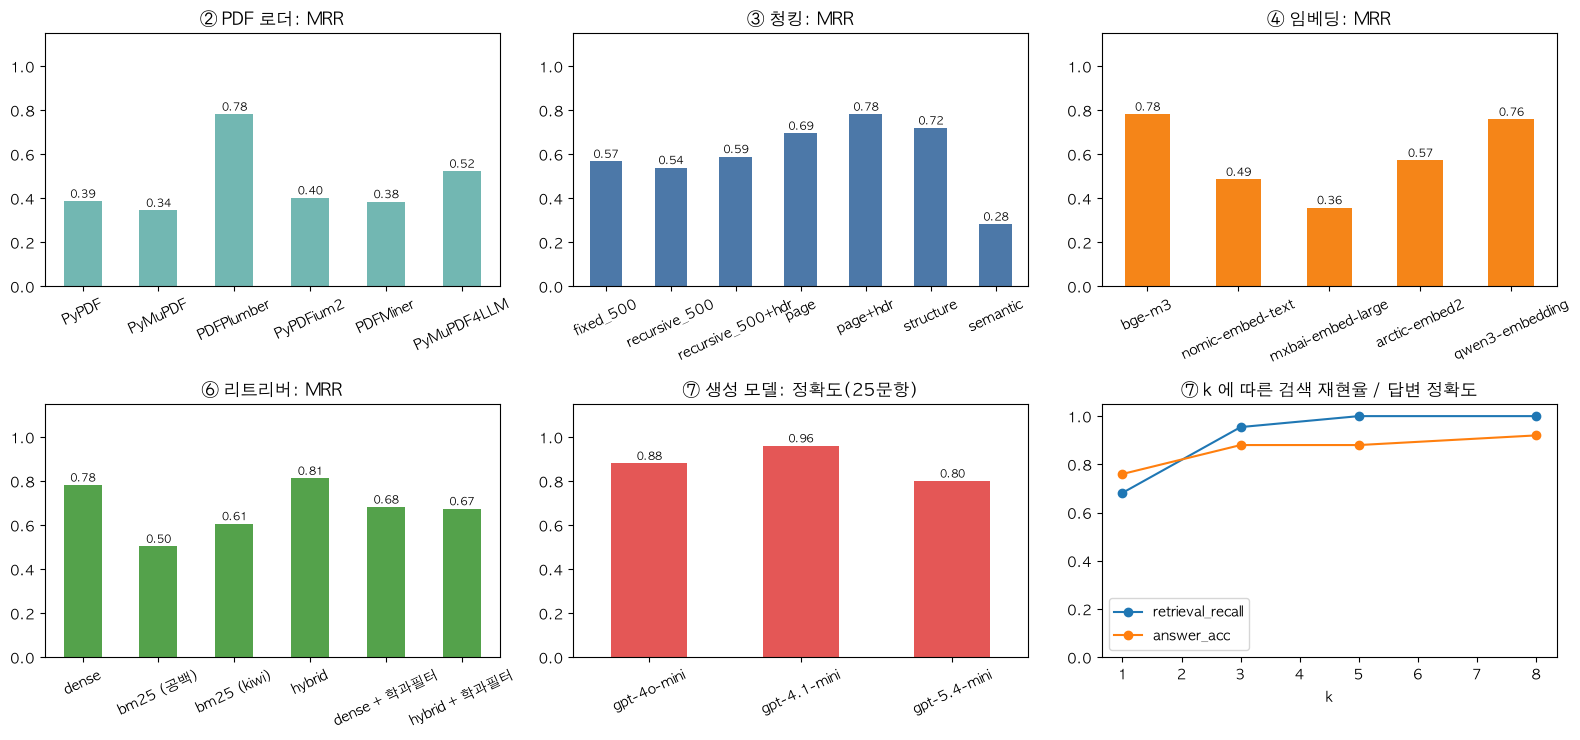

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
def bar(ax, s, title, color="#4c78a8"):
    s.plot.bar(ax=ax, color=color, rot=25); ax.set_title(title); ax.set_xlabel("")
    for p in ax.patches: ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
bar(axes[0, 0], RESULTS["parser"]["MRR"].rename(lambda n: n.replace("Loader", "")), "② PDF 로더: MRR", "#72b7b2")
bar(axes[0, 1], RESULTS["chunk"]["MRR"], "③ 청킹: MRR", "#4c78a8")
bar(axes[0, 2], RESULTS["embed"]["MRR"], "④ 임베딩: MRR", "#f58518")
bar(axes[1, 0], RESULTS["retrieval"]["MRR"], "⑥ 리트리버: MRR", "#54a24b")
bar(axes[1, 1], RESULTS["gen"]["acc_all"].rename(lambda n: n.split(":")[-1]), "⑦ 생성 모델: 정확도(25문항)", "#e45756")
RESULTS["k_sweep"][["retrieval_recall", "answer_acc"]].plot(ax=axes[1, 2], marker="o"); axes[1, 2].set_title("⑦ k 에 따른 검색 재현율 / 답변 정확도"); axes[1, 2].set_ylim(0, 1.05)
for ax in axes.flat[:5]: ax.set_ylim(0, 1.15)
plt.tight_layout(); plt.show()

### 8.2 우리 조합 선정

In [33]:
pf = RESULTS["parser"].loc[BEST_PARSER]
summary = pd.DataFrame([
    ("PDF 로더",   BEST_PARSER,  f"MRR {pf['MRR']:.3f} · 행 보존율 {pf['row_fidelity']:.2f}", "파서가 입력 품질과 메타데이터 추출을 결정"),
    ("청킹",       BEST_CHUNKER, f"MRR {chunk_df.loc[BEST_CHUNKER, 'MRR']:.3f}", "헤더(학과) 부착 효과를 3.3 표에서 확인"),
    ("임베딩",     BEST_EMBED,   f"MRR {embed_df.loc[BEST_EMBED, 'MRR']:.3f} · {DIM}차원", "다국어 모델 우위 · 속도/용량은 4장 표"),
    ("벡터스토어", "Chroma 등 (교체 가능)", f"MRR {RESULTS['vdb']['MRR'].min():.3f}~{RESULTS['vdb']['MRR'].max():.3f}", "규모가 작아 정확도 동일 → 필터·운영성으로 선택"),
    ("리트리버",   BEST_RETRIEVER_NAME, f"MRR {retr_df.loc[BEST_RETRIEVER_NAME, 'MRR']:.3f}", "Dense+BM25 결합이 안정적 · 필터는 질문 의도를 모르면 역효과"),
    ("생성 모델",  BEST_GEN,     f"정확도 {gen_df.loc[BEST_GEN, 'acc_all']:.2f} · {gen_df.loc[BEST_GEN, 'avg_sec']:.1f}s/질문", "정확도 우선, 동률이면 속도"),
], columns=["단계", "선정", "핵심 수치", "비고"]).set_index("단계")
display(summary)

,선정,핵심 수치,비고
단계,,,
PDF 로더,PDFPlumberLoader,MRR 0.782 · 행 보존율 1.00,파서가 입력 품질과 메타데이터 추출을 결정
청킹,page+hdr,MRR 0.782,헤더(학과) 부착 효과를 3.3 표에서 확인
임베딩,bge-m3,MRR 0.782 · 1024차원,다국어 모델 우위 · 속도/용량은 4장 표
벡터스토어,Chroma 등 (교체 가능),MRR 0.782~0.782,규모가 작아 정확도 동일 → 필터·운영성으로 선택
리트리버,hybrid,MRR 0.812,Dense+BM25 결합이 안정적 · 필터는 질문 의도를 모르면 역효과
생성 모델,openai:gpt-4.1-mini,정확도 0.96 · 1.6s/질문,"정확도 우선, 동률이면 속도"


### 8.3 최종 LCEL 체인과 RAG 전/후 비교

검색 → 컨텍스트 조립 → 프롬프트 → 모델 → 파싱을 **하나의 체인**으로 묶습니다. `RunnablePassthrough.assign` 은 입력 딕셔너리에 키를 하나씩 덧붙여 가므로 중간 결과(`docs`)를 끝까지 들고 갈 수 있습니다. 표에 없는 **새 질문**도 `LookupEmbeddings` 의 폴백으로 실제 Ollama 임베딩을 거칩니다.

In [34]:
llm = make_llm(BEST_GEN)
retrieve_step = RunnableLambda(lambda x: BEST_RETRIEVER.invoke(x["question"])[:GEN_K])
rag_chain = (RunnablePassthrough.assign(docs=retrieve_step)
             | RunnablePassthrough.assign(context=lambda x: format_docs(x["docs"]))
             | RunnablePassthrough.assign(answer=RAG_PROMPT | llm | StrOutputParser()))

def ask(question):
    r = rag_chain.invoke({"question": question})
    print(f"Q. {question}\nA. {r['answer']}\n   └ 근거 페이지 {[d.metadata['page'] for d in r['docs']]}")
    return r

for question in ["소프트웨어융합학과 3학년 2학기 네트워크실험의 학수번호는?",     # 평가셋에 없는 새 질문
                 "컴퓨터공학과 4학년 2학기 블록체인의 학수번호는?",
                 "학사경고를 받으면 어떤 불이익이 있나요?"]:
    ask(question); print()

Q. 소프트웨어융합학과 3학년 2학기 네트워크실험의 학수번호는?
A. 소프트웨어융합학과 3학년 2학기 네트워크실험의 학수번호는 704511입니다.
   └ 근거 페이지 [194, 193, 93, 71, 99]

Q. 컴퓨터공학과 4학년 2학기 블록체인의 학수번호는?
A. 컴퓨터공학과 4학년 2학기 블록체인의 학수번호는 101815입니다.
   └ 근거 페이지 [99, 98, 194, 71, 70]

Q. 학사경고를 받으면 어떤 불이익이 있나요?
A. 책자에서 확인할 수 없습니다.
   └ 근거 페이지 [4, 142, 3, 42, 34]



,RAG 없음,RAG 적용
type,,
multi,0.00,1.00
rule,0.22,0.89
table,0.00,1.00
unanswerable,0.67,1.00
전체,0.16,0.96


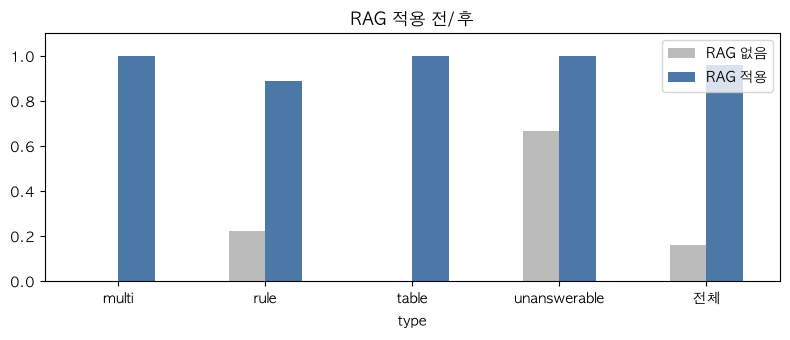

In [35]:
# RAG 전/후 정확도 비교 (같은 생성 모델, 같은 25문항)
no_ans, _ = run_chain(BEST_GEN, [dict(question=q["question"]) for q in QA], NORAG_PROMPT)
no_rag = pd.DataFrame([dict(id=q["id"], type=q["type"], ok=judge(q, a)) for q, a in zip(QA, no_ans)])
with_rag = gen_raw[gen_raw.model == BEST_GEN][["id", "type", "ok"]]
cmp_df = pd.DataFrame({"RAG 없음": no_rag.groupby("type").ok.mean(), "RAG 적용": with_rag.groupby("type").ok.mean()})
cmp_df.loc["전체"] = [no_rag.ok.mean(), with_rag.ok.mean()]
RESULTS["rag_vs_norag"] = cmp_df
display(cmp_df.style.format(precision=2).set_caption(f"{BEST_GEN} — 유형별 정확도"))
cmp_df.plot.bar(figsize=(8, 3.5), rot=0, color=["#bbbbbb", "#4c78a8"]); plt.ylim(0, 1.1); plt.title("RAG 적용 전/후"); plt.tight_layout(); plt.show()

> `unanswerable` 문항은 RAG 없이도 "모르겠다" 고 답하면 정답입니다. 반면 `table`/`rule` 문항은 **RAG 없이는 사실상 맞힐 수 없습니다.** 모델이 책자를 본 적이 없기 때문입니다.

### 8.4 LangChain 으로 만들어 보니

| LangChain 이 해결해 준 것 | 추상화가 새는 곳 |
|---|---|
| 로더·스플리터·임베딩·벡터스토어·리트리버가 **같은 인터페이스**라 교체가 쉽다 (5·6장) | **PDF 로더마다 반환 형식이 다르다** (PDFMiner 는 문서 1개) → 후처리 필요 (2장) |
| `EnsembleRetriever`, `BM25Retriever` 등 **검색 조합이 한 줄** | **벡터스토어 필터 문법·동작이 제각각** (사전/사후 필터, `fetch_k`) (5.3) |
| LCEL `\|`, `batch`, 콜백으로 **병렬 호출·측정**이 간단 (7장) | 구조 기반 청킹 같은 **도메인 로직은 직접 구현** (3장) |
| 모델 교체(`ChatOpenAI` ↔ `ChatOllama`)가 한 줄 | **패키지가 잘게 쪼개져** 있고 버전마다 import 경로가 바뀐다 (`langchain_classic` 등) |

> 직접 구현했던 앞선 노트북(`local_rag_lab.ipynb`)과 결과를 비교해 보세요. **같은 평가셋에서 점수가 비슷하다면 LangChain 은 성능이 아니라 "교체 가능성과 생산성"을 주는 도구**라는 뜻입니다.

### 8.5 (선택) 대화 루프

```python
while True:
    q = input("질문 (종료: q) > ")
    if q.strip().lower() in ("q", "quit", "exit"): break
    ask(q)
```

## 9. 실습 과제와 마무리

### 과제
1. **로더 추가** — `UnstructuredPDFLoader`(`strategy="hi_res"`), `DoclingLoader`(`langchain-docling`) 를 `LOADERS` 에 추가해서 표 복원 품질과 MRR 을 비교하세요. (모델 다운로드가 필요하고 무겁습니다)
2. **로더 후처리** — `PDFPlumberLoader` 결과에서 표를 마크다운으로 변환한 뒤 청킹해 보세요. 행 보존율과 MRR 이 오르나요?
3. **필터 자동화** — `detect_dept` 는 정규식 수준입니다. 질문 의도(학과 표를 묻는가?)를 분류하는 단계를 `DeptFilterRetriever` 앞에 추가하세요.
4. **고급 리트리버** — `MultiQueryRetriever`(질문 다중 생성), `ParentDocumentRetriever`(작게 찾고 크게 읽기), `ContextualCompressionRetriever`(재랭킹/압축)를 6장 표에 추가해 비교하세요.
5. **평가 확장** — 질문 5개를 더 추가하고, 가장 많이 틀리는 유형을 분석하세요. 평가셋 25문항은 방향을 보는 용도입니다.

### 한계와 다음 단계
- 평가셋이 작아 점수 차이가 작으면 우연일 수 있습니다. 실무에서는 수백 문항 + LLM-as-judge 를 씁니다.
- 키워드 채점은 표기가 다른 정답을 오답 처리할 수 있습니다. (`A|B` 로 완화)
- 다음 주제: RAG 평가 자동화(RAGAS 등), 에이전트형 RAG(LangGraph).

### FAQ / 트러블슈팅
| 증상 | 해결 |
|---|---|
| `ConnectionError` (Ollama) | Ollama 앱 실행 확인 (`ollama serve`) |
| `model not found` (Ollama) | 1.2 셀이 알려 준 `ollama pull ...` 실행 |
| `OPENAI_API_KEY 가 없습니다` | `.env` 생성 → `OPENAI_API_KEY=sk-...` → 커널 재시작 |
| OpenAI `model_not_found` / 접근 불가 | 계정에서 쓸 수 있는 모델로 `GEN_MODELS`, `FAST_MODEL` 수정 |
| OpenAI `429 RateLimit` | `MAX_WORKERS` 를 줄이세요 (예: 3) |
| 첫 실행이 너무 오래 걸림 | 2.3 의 `LOADERS` 에서 느린 로더(`PDFMinerLoader`, `PyMuPDF4LLMLoader`)를 잠시 빼거나, `EMBED_MODELS` 를 줄이세요. 이후엔 `.cache/` 덕분에 빠릅니다. |
| `ImportError: EnsembleRetriever` | LangChain 버전에 따라 `langchain_classic.retrievers` ↔ `langchain.retrievers` 경로가 다릅니다. |
| 한글이 □ 로 깨짐 (그래프) | 1.2 셀의 폰트 후보에 설치된 한글 폰트 추가 |
| 캐시를 지우고 처음부터 | `.cache/` 폴더 삭제 |